# Fashion-MNIST — 10 Specialist CNN dan Generalist CNN dengan Pareto Exploration & Expansion

Notebook ini memakai **CNN ringan** (bukan ResNet-18) untuk mempercepat penelitian algoritma. Jalankan sel secara **berurutan**, mulai dari atas. Dataset spesialis dan teacher tetap sama seperti versi sebelumnya.

- **Seluruh 10 specialist / teacher (kelas 0–9)** masing-masing menjalani PCGrad, MGDA, FAMO (exploration), lalu MINRES dan Alfa tengah (expansion jika kandidat pasangan tersedia). Dua tugas untuk setiap specialist: **kelas target** vs **bukan kelas target**.
- **Generalis** mempunyai **10 head × 2 logit per head**. Untuk optimasi multiobjektif, ada **10 tugas independen**: BCE rata-rata dua logit untuk *masing-masing kelas*. Jadi PCGrad/MGDA/FAMO/MINRES/Alfa tengah mempertimbangkan semua 10 kelas, **bukan lagi 2 loss agregat**.
- Grafik generalis tetap dapat menampilkan proyeksi **rata-rata BCE hadir vs tidak hadir** untuk memudahkan visualisasi 2D, tetapi proyeksi tersebut **bukan Pareto front 10 dimensi**. Grafik per kelas juga disediakan. Semua pemilihan pemenang Generalist memakai minimax **10 loss validasi per kelas**.
- Pasangan hasil exploration untuk expansion lebih mengutamakan titik *nondominated* (10 dimensi pada generalis). Bila tidak ada pasangan memadai, tersedia fallback yang dilabeli jelas; tidak otomatis berarti Pareto-optimal.
- Validasi digunakan untuk checkpoint/pemilihan; test digunakan sesudah model terpilih. MINRES merupakan eksperimen Hessian-vector product, dapat gagal secara numerik. `SECONDS` hanya diperiksa **antar-ronde**, bukan menghentikan solver yang sedang berjalan.

Membutuhkan PyTorch, torchvision, NumPy, Matplotlib, dan SciPy. Fashion-MNIST diunduh saat pertama kali dijalankan (`download=True`).


**Modifikasi midpoint refinement:** metode tambahan `Alfa tengah + MGDA` dan `Alfa tengah + FAMO`. Keduanya melakukan weighted-sum 60 langkah lalu refinement 60 langkah mulai dari bobot model midpoint. Tidak menjamin masuk true Pareto front; dicek nondominated pada kandidat validasi.


In [1]:
# math menyediakan ceil dan log, random mengacak pergeseran dan urutan PCGrad, time mengukur durasi.
import math, random, time
# np mengolah array gambar dan label. torch menyediakan tensor, perangkat komputasi, dan gradien.
import numpy as np
import torch
# nn menyediakan lapisan jaringan. F menyediakan operasi padding, fungsi loss, dan softmax.
import torch.nn as nn
import torch.nn.functional as F
# plt menggambar hasil. datasets memuat Fashion-MNIST.
import matplotlib.pyplot as plt
from torchvision import datasets

In [2]:
from copy import deepcopy
from collections import deque
from scipy.sparse.linalg import LinearOperator, minres
import inspect

In [3]:
dev = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Perangkat:', dev)

Perangkat: cuda


In [4]:
# Kesepuluh kelas diproses berurutan; model CNN agar training per kelas lebih ringan.
CFG = dict(
    SEED=0, BS=128, LR=0.001, EPOCHS=4, N_SPEC_HARD=2000,
    STEPS=60, MIDPOINT_REFINE_STEPS=60, ROUNDS=8, TARGET=0.15, WIDTH=0.02, PATIENCE=3,
    ALPHA_WINDOW=8, SECONDS=180, MINRES_ITERS=24,
    MINRES_BS=8, DAMP=0.1, STEP_SIZE=0.05,
    PLOT_SPECIALISTS=True,
    SAVE_TEACHERS=True,
    TEACHER_DIR='fashion_cnn_teachers',
    PROGRESS_EVERY=100,   # Cetak batch training tiap 100 batch (0 untuk menonaktifkan).
)


In [5]:
# set_seed menerima s dari SEED (ditambah indeks kelas untuk spesialis). Fungsi mengatur generator
# acak Python, NumPy dan PyTorch tanpa nilai balik.
def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(s)
set_seed(CFG['SEED'])

## Data spesialis
Data latih mencakup gambar tunggal serta potongan pakaian dari tumpukan. Validasi memilih model. Data uji hanya dipakai setelah pilihan selesai.

In [6]:
# CANVAS dan DS adalah ukuran sisi kanvas dan pakaian dalam piksel untuk penempatan, crop, padding, dan prep.
CANVAS, DS = 56, 28           # kanvas diperluas (sebelumnya 36), digit tetap 28x28 asli
# MAX_OVERLAP menjadi sasaran batas tumpang tindih saat mencari posisi di make_multi_flexible.
MAX_OVERLAP = 0.25            # maks. overlap kotak antar pakaian (fraksi luas 28x28)
# K_MIN dan K_MAX menentukan rentang jumlah pakaian per kanvas. K_MAX juga menentukan banyak slot label dan posisi.
K_MIN, K_MAX = 2, 4
# CLASS_NAMES memetakan indeks label Fashion-MNIST ke nama untuk laporan dan judul grafik.
CLASS_NAMES = ('T-shirt/top','Trouser','Pullover','Dress','Coat',
               'Sandal','Shirt','Sneaker','Bag','Ankle boot')

In [7]:
# fashion_tr dan fashion_te adalah dataset asli dari torchvision. Atribut data dan targets dibaca di bawah.
fashion_tr = datasets.FashionMNIST('./data', train=True, download=True)
fashion_te = datasets.FashionMNIST('./data', train=False, download=True)
# all_tr_x/all_tr_y menyimpan gambar/label untuk pembagian latih-validasi. fa_te_x/fa_te_y untuk tumpukan dan evaluasi uji.
all_tr_x, all_tr_y = fashion_tr.data.numpy(), fashion_tr.targets.numpy()
fa_te_x, fa_te_y = fashion_te.data.numpy(), fashion_te.targets.numpy()

In [8]:
# perm adalah urutan indeks acak dari SEED. Indeks yang sama menjaga pasangan gambar dan label saat dibagi.
perm = np.random.RandomState(CFG['SEED']).permutation(len(all_tr_x))
# fa_tr_x/fa_tr_y berisi 54.000 pasangan latih untuk gambar tunggal dan pembuatan tumpukan.
fa_tr_x, fa_tr_y = all_tr_x[perm[:54000]], all_tr_y[perm[:54000]]
# fa_val_x/fa_val_y adalah sisa pasangan dari perm untuk membuat tumpukan validasi.
fa_val_x, fa_val_y = all_tr_x[perm[54000:]], all_tr_y[perm[54000:]]

In [9]:
# make_multi_flexible membuat n kanvas dari imgs dan labels milik bagian data yang dipilih pemanggil.
# k_min/k_max membatasi jumlah item, seed mengatur undian, max_overlap dan n_tries mengatur pencarian posisi.
# Hasilnya tiga array NumPy berurutan (gambar, ID kelas per slot, koordinat per slot), diterima keluarga Xg/Yg/Pg atau Xh_raw/Yh_raw/Ph_raw.
def make_multi_flexible(imgs, labels, n, k_min=K_MIN, k_max=K_MAX, seed=1,
                        max_overlap=MAX_OVERLAP, n_tries=30):
    # rng adalah generator lokal dari seed untuk mengundi jumlah, indeks, dan posisi pakaian.
    rng = np.random.RandomState(seed)
    # X menyimpan piksel tiap kanvas. Y menyimpan ID kelas dan P menyimpan (baris, kolom) tiap slot.
    # -1 menandai slot kosong.
    X = np.zeros((n, CANVAS, CANVAS), dtype=np.uint8)
    Y = np.full((n, k_max), -1, dtype=np.int64)
    P = np.full((n, k_max, 2), -1, dtype=np.int64)
    # off adalah koordinat awal terbesar agar pakaian tetap muat di kanvas.
    off = CANVAS - DS
    # i memilih kanvas keluaran. k_items adalah jumlah pakaian yang diundi untuk kanvas itu.
    for i in range(n):
        k_items = rng.randint(k_min, k_max + 1)
        # idx berisi indeks sumber dari imgs/labels. boxes mengingat posisi yang sudah ditempati pada kanvas i.
        idx = rng.randint(0, len(imgs), size=k_items)
        boxes = []
        # k adalah nomor slot keluaran, j indeks gambar asli dari idx untuk mengisi slot k.
        for k, j in enumerate(idx):
            # best dan best_ov menyimpan posisi dengan overlap terkecil beserta nilainya selama pencarian.
            best, best_ov = None, 9.0
            # _ menghitung percobaan sampai n_tries. py dan px adalah calon baris dan kolom kiri atas.
            for _ in range(n_tries):          # cari posisi dengan overlap kecil
                py, px = rng.randint(0, off + 1), rng.randint(0, off + 1)
                # by dan bx berasal dari boxes. ov adalah fraksi overlap terbesar calon posisi terhadap pakaian sebelumnya.
                ov = max([max(0, DS - abs(py - by)) * max(0, DS - abs(px - bx)) / (DS * DS)
                          for by,bx in boxes], default=0.0)
                if ov < best_ov:
                    best, best_ov = (py,px), ov
                if ov <= max_overlap:
                    break
            # py dan px mengambil posisi terbaik yang ditemukan, termasuk bila batas overlap belum tercapai.
            py, px = best
            boxes.append((py, px))
            # patch menjumlahkan piksel lama dan imgs[j] dalam 16 bit. Hasil dibatasi ke 255 untuk X,
            # lalu label dan posisi dicatat.
            patch = X[i, py:py+DS, px:px+DS].astype(np.uint16) + imgs[j].astype(np.uint16)
            X[i, py:py+DS, px:px+DS] = np.minimum(patch, 255).astype(np.uint8)
            Y[i, k] = labels[j]
            P[i, k] = [py, px]
    return X, Y, P

In [10]:
# crop_pad menerima kanvas X, posisi P, dan nomor slot k dari pembuat data spesialis atau teacher_presence.
# Hasilnya array seukuran X berisi crop slot k di tengah kanvas hitam. Slot kosong menghasilkan kanvas hitam.
def crop_pad(X, P, k):
    # out menampung hasil crop. o adalah offset untuk menempatkannya di tengah.
    out = np.zeros_like(X)
    o = (CANVAS - DS) // 2
    # i memilih kanvas. y dan x berasal dari P[i,k] untuk menentukan area piksel sumber.
    for i in range(len(X)):
        if P[i, k, 0] != -1:
            y, x = P[i, k]
            out[i, o:o+DS, o:o+DS] = X[i, y:y+DS, x:x+DS]
    return out

In [11]:
# pad_fashion menerima imgs dari fa_tr_x atau fa_te_x dan mengembalikan kanvas terpusat untuk Xs atau Xte_single.
def pad_fashion(imgs):
    # out adalah kanvas kosong per gambar, o adalah offset tempat menyalin imgs ke tengah.
    out = np.zeros((len(imgs), CANVAS, CANVAS), np.uint8)
    o = (CANVAS - DS) // 2
    out[:, o:o+DS, o:o+DS] = imgs
    return out

In [12]:
# Data spesialis: gambar tunggal bersih + crop dari tumpukan, semuanya berlabel ASLI
# n_h menghitung jumlah kanvas sumber crop dari batas N_SPEC_HARD dan jumlah slot maksimum.
n_h = (CFG['N_SPEC_HARD'] + K_MAX - 1) // K_MAX
# Xh_raw/Yh_raw/Ph_raw adalah kanvas, kelas, dan posisi sintetis dari data latih untuk membuat contoh spesialis.
Xh_raw, Yh_raw, Ph_raw = make_multi_flexible(fa_tr_x, fa_tr_y, n_h, seed=4)
# Xs_h/Ys_h mula-mula daftar kumpulan crop/label per slot. k memilih slot, v menandai gambar yang memiliki slot itu.
Xs_h, Ys_h = [], []
for k in range(K_MAX):
    v = Ph_raw[:, k, 0] != -1
    Xs_h.append(crop_pad(Xh_raw, Ph_raw, k)[v]); 
    Ys_h.append(Yh_raw[v, k])
# Xs_h dan Ys_h kemudian menjadi array crop dan label yang digabung, dipotong sesuai batas, lalu dipasangkan dengan data bersih.
Xs_h = np.concatenate(Xs_h)[:CFG['N_SPEC_HARD']]
Ys_h = np.concatenate(Ys_h)[:CFG['N_SPEC_HARD']]
# Xs memasangkan kanvas bersih dan crop dalam satu array gambar. Ys menyusun label asli dalam urutan yang sama.
Xs = np.concatenate([pad_fashion(fa_tr_x), Xs_h])
Ys = np.concatenate([fa_tr_y, Ys_h])

In [13]:
# Tensor disimpan di CPU. Hanya batch yang sedang diproses dipindahkan ke dev.
train = torch.from_numpy(Xs), torch.from_numpy(Ys)
valid = torch.from_numpy(pad_fashion(fa_val_x)), torch.from_numpy(fa_val_y)
test = torch.from_numpy(pad_fashion(fa_te_x)), torch.from_numpy(fa_te_y)
for c in range(len(CLASS_NAMES)):
    print('Spesialis:', CLASS_NAMES[c], '| Total gbr latih:', len(Ys), '| gbr kelas target:', np.sum(Ys == c), '| gbr kelas lainnya:', np.sum(Ys != c))


Spesialis: T-shirt/top | Total gbr latih: 55476 | gbr kelas target: 5518 | gbr kelas lainnya: 49958
Spesialis: Trouser | Total gbr latih: 55476 | gbr kelas target: 5556 | gbr kelas lainnya: 49920
Spesialis: Pullover | Total gbr latih: 55476 | gbr kelas target: 5561 | gbr kelas lainnya: 49915
Spesialis: Dress | Total gbr latih: 55476 | gbr kelas target: 5582 | gbr kelas lainnya: 49894
Spesialis: Coat | Total gbr latih: 55476 | gbr kelas target: 5541 | gbr kelas lainnya: 49935
Spesialis: Sandal | Total gbr latih: 55476 | gbr kelas target: 5555 | gbr kelas lainnya: 49921
Spesialis: Shirt | Total gbr latih: 55476 | gbr kelas target: 5533 | gbr kelas lainnya: 49943
Spesialis: Sneaker | Total gbr latih: 55476 | gbr kelas target: 5558 | gbr kelas lainnya: 49918
Spesialis: Bag | Total gbr latih: 55476 | gbr kelas target: 5528 | gbr kelas lainnya: 49948
Spesialis: Ankle boot | Total gbr latih: 55476 | gbr kelas target: 5544 | gbr kelas lainnya: 49932


In [14]:
# 1 fungsiprep() menyiapkan gambar sebelum dimasukkan ke model. 
# 1 Gambar diubah ke format yang bisa dibaca model, lalu bisa digeser sedikit secara acak.
# 2 xb atau x-batch adalah sekumpulan gambar dalam bentuk tensor. 
# 2 Pada notebook ini, ukurannya (jumlah gambar, 56, 56). Setiap piksel biasanya bernilai dari 0 sampai 255.
# 3 shift adalah batas pergeseran acak dalam satuan piksel. Nilai awalnya 0, yang berarti gambar tidak digeser.   
# 4 Outputnya adalah tensor x yang siap masuk ke model. Ukurannya menjadi (jumlah gambar, 1, 56, 56). 
# 4 Angka 1 menunjukkan satu kanal warna karena gambar berwarna abu-abu. Nilai pikselnya sudah berada dalam rentang 0 sampai 1.
def prep(xb, shift=0): 
    # x berasal dari xb, dikonversi ke .float(), bagi .div(255), .unsqueeze(1) menambahkan dimensi kanal pada posisi ke-1
    x = xb.float().div(255).unsqueeze(1)
    if shift: 
        # sy dan sx adalah pergeseran acak vertikal/horizontal untuk seluruh batch. x dipad lalu dipotong kembali seukuran CANVAS.
        sy, sx = random.randint(-shift, shift), random.randint(-shift, shift) # cari int buat digeser
        x = F.pad(x, (shift,)*4) # padding biar ga kepotong pas digeser
        x = x[:, :, shift+sy:shift+sy+CANVAS, shift+sx:shift+sx+CANVAS] # baru deh dipotong
    return x # satu x-batch yang sudah digeser random sejauh shift

## Arsitektur CNN dan definisi multiobjective

- **Specialist (tiap kelas):** backbone CNN 1×56×56 → 32 fitur; **2 head**, masing-masing menghasilkan satu logit. Dua loss BCE: kelas target hadir, kelas target tidak hadir.
- **Generalis:** memakai backbone CNN yang sama, tetapi **10 head** dengan dua logit per kelas (hadir/tidak hadir). Output `(B,10,2)`.
- **Generalist multiobjective:** setiap head dihitung sebagai **satu tugas**, yaitu rata-rata BCE dua logit untuk satu kelas. Maka `head_losses` menghasilkan **10 loss**, sehingga MGDA, PCGrad, dan FAMO melibatkan 10 tujuan. MINRES/Alfa tengah juga memakai vektor alpha sepanjang 10.
- **Grafik generalis 2D:** hanya proyeksi rata-rata BCE *hadir vs tidak hadir* semua kelas; gunakan loss per kelas dan uji dominasi 10 dimensi untuk keputusan Pareto sebenarnya.


In [15]:
class Specialist(nn.Module):
    def __init__(self):
        super().__init__()
        # CNN asli dari notebook; satu convolution, bukan ResNet-18.
        # Dari input 56x56: AvgPool -> 28x28 -> Conv stride 2 -> 12x12
        # -> AvgPool -> 6x6 -> Flatten(288) -> fitur dimensi 32.
        self.backbone = nn.Sequential(
            nn.AvgPool2d(2),
            nn.Conv2d(1, 8, kernel_size=5, stride=2),
            nn.Softplus(),
            nn.AvgPool2d(2),
            nn.Flatten(),
            nn.Linear(8 * 6 * 6, 32),
            nn.Softplus(),
        )
        self.heads = nn.ModuleList([
            nn.Linear(32, 1),
            nn.Linear(32, 1),
        ])

    def forward(self, x):
        features = self.backbone(x)
        return torch.cat([head(features) for head in self.heads], dim=1)


In [16]:
def loss_components(model, batch, class_id=None):
    """(loss_tugas, proyeksi_2d). Generalist: 10 tugas, 2 sumbu hanya untuk plot."""
    images, labels = batch
    scores = model(prep(images.to(dev)))

    if labels.ndim == 2:
        # Generalist: 10 head x 2 logit, satu objektif per kelas.
        # Pembuatan target soft training dan label hard validasi/uji tetap sama.
        present = labels.to(device=dev, dtype=scores.dtype)
        assert scores.ndim == 3 and scores.shape[1:] == (len(CLASS_NAMES), 2)
        targets = torch.stack([present, 1.0 - present], dim=2)
        bce = F.binary_cross_entropy_with_logits(scores, targets, reduction='none')
        per_class = bce.mean(dim=(0, 2))    # (10,) -- objektif Pareto sesungguhnya
        projection_xy = bce.mean(dim=(0, 1)) # (2,) -- hanya proyeksi untuk grafik
        return per_class, projection_xy

    if class_id is None:
        raise ValueError('Specialist membutuhkan class_id eksplisit (0..9).')
    positive = labels.to(dev) == int(class_id)
    targets = torch.stack([positive, ~positive], dim=1).to(scores.dtype)
    bce = F.binary_cross_entropy_with_logits(scores, targets, reduction='none')
    objectives = bce.mean(dim=0)            # (2,) kelas target vs bukan target
    return objectives, objectives


def head_losses(model, batch, class_id=None):
    """Mengembalikan tensor objektif: (2,) Specialist atau (10,) Generalist."""
    return loss_components(model, batch, class_id=class_id)[0]


In [17]:
@torch.no_grad()
def evaluate(model, data, class_id=None, return_components=False):
    """Evaluasi ber-batch: objektif asli dan proyeksi 2D, weighted by batch size.

    Secara default mengembalikan proyeksi 2D agar kode ringkasan lama tetap bisa
    memakai evaluate(...). Untuk memilih checkpoint gunakan return_components=True.
    """
    previous_mode = model.training
    model.eval()
    try:
        objective_sum = None
        projection_sum = torch.zeros(2, device=dev)
        n_total = 0
        for images, labels in zip(*(v.split(CFG['BS']) for v in data)):
            objectives, xy = loss_components(model, (images, labels), class_id)
            if objective_sum is None:
                objective_sum = torch.zeros_like(objectives)
            objective_sum += len(labels) * objectives
            projection_sum += len(labels) * xy
            n_total += len(labels)
        if n_total == 0:
            raise ValueError('Dataset evaluasi kosong.')
        objective_array = (objective_sum / n_total).cpu().numpy()
        xy_array = (projection_sum / n_total).cpu().numpy()
        return (objective_array, xy_array) if return_components else xy_array
    finally:
        model.train(previous_mode)


In [18]:
def flat_grads(losses, params):
    """Matriks gradien: satu baris per objektif, satu kolom per parameter."""
    params = tuple(params)  # aman jika pemanggil mengirim generator .parameters()
    gs = []
    for loss in losses:
        grads = torch.autograd.grad(
            loss, params, retain_graph=True, allow_unused=True
        )
        gs.append(torch.cat([
            (g if g is not None else torch.zeros_like(p)).reshape(-1)
            for g, p in zip(grads, params)
        ]))
    return torch.stack(gs, dim=0)


In [19]:
# pcgrad menerima matriks gradien G dari flat_grads. Hasilnya vektor jumlah gradien setelah proyeksi, untuk g di train_step.
def pcgrad(G):
    # T adalah jumlah baris G. out menyalin G agar tiap baris dapat diperbarui.
    T = len(G); out = G.clone()
    # i memilih tugas yang dikoreksi, j memilih tugas pembanding secara acak.
    for i in range(T):
        for j in random.sample(range(T), T):
            if j == i: continue
            # dot mengukur keselarasan out[i] dan G[j]. Nilai negatif memicu pengurangan komponen yang bertentangan.
            dot = (out[i] * G[j]).sum()
            if dot < 0:
                out[i] = out[i] - dot / (G[j].norm() ** 2 + 1e-12) * G[j]
    return out.sum(0)

In [20]:
# mgda_weights menerima G dari flat_grads dan batas iterasi iters. Hasilnya bobot a untuk kombinasi gradien a @ G.
def mgda_weights(G, iters=50):
    # M berisi hasil kali dalam antargradien. T jumlah tugas untuk menentukan ukuran a.
    M = G @ G.T; T = len(G)
    # a dimulai dengan bobot seragam, lalu diperbarui untuk memperkecil norma gradien gabungan.
    a = torch.ones(T, device=G.device) / T
    # _ menghitung iterasi. i memilih komponen terkecil dari M @ a sebagai arah menuju satu tugas.
    for _ in range(iters):
        i = torch.argmin(M @ a)
        # e memberi bobot satu pada tugas i. d adalah perubahan dari a menuju e, gamma menentukan panjang langkah sepanjang d.
        e = torch.zeros_like(a); 
        e[i] = 1
        d = e - a
        gamma = torch.clamp(-(d @ M @ a) / (d @ M @ d + 1e-12), 0, 1)
        a = a + gamma * d
    return a

In [21]:
# FAMO menyimpan dan menyesuaikan bobot tugas selama pelatihan bila METHOD memilih famo.
class FAMO:
    # __init__ menerima self, jumlah tugas T dari train_step, lr untuk Adam internal dan gamma untuk weight decay. Ia mengisi atribut instance.
    def __init__(self, T, lr=0.025, gamma=1e-3):
        # self.w adalah skor bobot yang dilatih. self.opt mengoptimalkan skor ini dan self.eps menjaga log dan pembagian tetap terdefinisi.
        self.w = torch.zeros(T, device=dev, requires_grad=True)
        self.opt = torch.optim.Adam([self.w], lr=lr, weight_decay=gamma)
        self.eps = 1e-8
    # weighted menerima self dan tensor losses hasil stack loss tiap tugas. Hasilnya loss skalar untuk backward di train_step.
    def weighted(self, losses):
        # D adalah losses ditambah eps, z adalah bobot tugas ternormalisasi dari self.w, c adalah faktor normalisasi tanpa gradien.
        D = losses + self.eps
        z = F.softmax(self.w, -1)
        c = (z / D).sum().detach()
        return (D.log() * z / c).sum()
    # update menerima self, prev dan curr (loss per tugas sebelum dan sesudah langkah model). Ia memperbarui self.w tanpa nilai balik.
    def update(self, prev, curr):
        # delta mengukur penurunan log-loss per tugas. d mengubah delta menjadi gradien untuk self.w.grad yang dipakai self.opt.
        delta = (prev + self.eps).log() - (curr + self.eps).log()
        with torch.enable_grad():
            d = torch.autograd.grad(F.softmax(self.w, -1), self.w, grad_outputs=delta.detach())[0]
        self.opt.zero_grad(); self.w.grad = d; self.opt.step()

In [22]:
def train_step(model, optimizer, batch, method, famo=None, alpha=None, class_id=None):
    """Satu langkah optimasi: 2 loss specialist atau 10 loss generalist."""
    model.train()
    losses = head_losses(model, batch, class_id=class_id)
    optimizer.zero_grad(set_to_none=True)

    if method in ('MGDA', 'PCGrad'):
        shared = list(model.backbone.parameters())
        G = flat_grads(losses, shared)
        if method == 'MGDA':
            alpha = mgda_weights(G).detach()
            combined = alpha @ G
        else:
            combined = pcgrad(G) / len(losses)
        # Head masing-masing belajar loss-nya sendiri; gradien backbone diatur
        # eksplisit menurut PCGrad/MGDA. Untuk 10 head, mean memberi skala 1/10.
        losses.mean().backward()
        offset = 0
        for param in shared:
            size = param.numel()
            param.grad = combined[offset:offset + size].view_as(param).clone()
            offset += size
    elif method == 'FAMO':
        if famo is None:
            raise ValueError('Metode FAMO membutuhkan state FAMO.')
        alpha = famo.w.detach().softmax(0)
        famo.weighted(losses).backward()
        # Sebelum dan sesudah optimizer harus memakai mode yang sama. Tidak
        # merusak statistik BatchNorm jika backbone diganti lagi di masa depan.
        model.eval()
        with torch.no_grad():
            before = head_losses(model, batch, class_id=class_id)
    else:
        if alpha is None or alpha.numel() != losses.numel():
            raise ValueError(f'Alfa tengah membutuhkan {len(losses)} bobot alpha.')
        (alpha @ losses).backward()

    optimizer.step()
    if method == 'FAMO':
        with torch.no_grad():
            after = head_losses(model, batch, class_id=class_id)
        famo.update(before, after)
        model.train()
    return None if alpha is None else alpha.detach().cpu().numpy()


In [23]:
def checkpoint(model, name, alpha=None, valid=valid, class_id=None):
    """Snapshot validasi; Pareto/minimax menggunakan 2 atau 10 objektif asli."""
    objectives, xy = evaluate(model, valid, class_id=class_id, return_components=True)
    alpha_copy = None if alpha is None else np.asarray(alpha, dtype=np.float32).copy()
    return dict(
        name=name, xy=xy, objectives=objectives,
        score=float(np.max(objectives)), alpha=alpha_copy,
        state={k: v.detach().cpu().clone() for k, v in model.state_dict().items()},
    )


In [24]:
def explore(initial, method, train=train, valid=valid, class_id=None):
    """Independent initialization; spesialis 2 tujuan, generalis 10 tujuan."""
    seed = CFG['SEED'] + (class_id if class_id is not None else 0)
    set_seed(seed)
    model = deepcopy(initial)
    optimizer = torch.optim.AdamW(model.parameters(), lr=CFG['LR'])
    n_tasks = len(CLASS_NAMES) if class_id is None else 2
    famo = FAMO(n_tasks) if method == 'FAMO' else None
    history = []
    label = 'Generalis' if class_id is None else CLASS_NAMES[class_id]
    for epoch in range(CFG['EPOCHS']):
        start_epoch = time.perf_counter()
        recent = deque(maxlen=CFG['ALPHA_WINDOW'])
        batches = torch.randperm(len(train[1])).split(CFG['BS'])
        print(f'[{label}] {method} epoch {epoch + 1}/{CFG["EPOCHS"]} ({len(batches)} batch)', flush=True)
        for batch_no, ids in enumerate(batches, 1):
            alpha = train_step(
                model, optimizer, (train[0][ids], train[1][ids]),
                method, famo=famo, class_id=class_id,
            )
            if alpha is not None:
                recent.append(alpha)
            progress = CFG['PROGRESS_EVERY']
            if progress and (batch_no % progress == 0 or batch_no == len(batches)):
                print(f'    batch {batch_no}/{len(batches)} | {time.perf_counter()-start_epoch:.1f}s', flush=True)
        cp = checkpoint(model, method,
                        np.mean(recent, axis=0) if recent else None,
                        valid=valid, class_id=class_id)
        history.append(cp)
        print(f'    selesai epoch {epoch + 1}: minimax valid={cp["score"]:.5f}', flush=True)
    return history


In [25]:
def plot_exploration(class_id, start, paths):
    """Tiga panel terpisah; skala X/Y sama untuk perbandingan intra-kelas."""
    methods = ('FAMO', 'MGDA', 'PCGrad')
    all_xy = np.vstack([
        np.array([p['xy'] for p in [start] + paths[m]]) for m in methods
    ])
    xmin, ymin = all_xy.min(axis=0)
    xmax, ymax = all_xy.max(axis=0)
    dx = max(xmax - xmin, 1e-4) * 0.06
    dy = max(ymax - ymin, 1e-4) * 0.06
    fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharex=True, sharey=True)
    for ax, method in zip(axes, methods):
        xy = np.array([p['xy'] for p in [start] + paths[method]])
        ax.plot(xy[:, 0], xy[:, 1], 'o-', label=method)
        ax.scatter(*start['xy'], marker='*', s=180, color='black', zorder=5, label='Awal')
        for epoch, pt in enumerate(xy):
            ax.annotate('Awal' if epoch == 0 else f'E{epoch}', pt,
                        xytext=(6, 6), textcoords='offset points', fontsize=9)
        ax.set(xlim=(xmin-dx, xmax+dx), ylim=(ymin-dy, ymax+dy),
               title=method, xlabel=f'Loss {CLASS_NAMES[class_id]}')
        ax.grid(alpha=0.3)
        ax.legend()
    axes[0].set_ylabel(f'Loss bukan {CLASS_NAMES[class_id]}')
    fig.suptitle(f'Exploration Specialist {class_id}: {CLASS_NAMES[class_id]}', fontsize=14)
    plt.tight_layout()
    plt.show()


## Memilih pasangan untuk expansion

- Pada **Specialist**, pasangan dipilih dari FAMO dan MGDA berdasarkan hubungan trade-off dua objektif. Jika tidak tersedia, fallback dapat dipakai dan ditandai bukan jaminan Pareto.
- Pada **Generalis**, *nondominated* dicek dari **10 objektif per kelas**, bukan proyeksi X/Y. Pasangan FAMO–MGDA dipilih berdasarkan trade-off seluruh kelas dan perbedaan vektor alpha 10 dimensi. Fallback tetap tersedia dan ditandai.


In [26]:
def dominates(a, b):
    """a mendominasi b dalam semua objective yang tersedia (2 atau 10)."""
    a_obj = np.asarray(a['objectives'])
    b_obj = np.asarray(b['objectives'])
    return bool(np.all(a_obj <= b_obj) and np.any(a_obj < b_obj))


In [27]:
def choose_pair(points, allow_fallback=False):
    """Cari pasangan FAMO/MGDA; fallback dipakai pada 10 Specialist bila perlu."""
    front = [p for p in points if not any(dominates(q, p) for q in points)]
    eligible = sorted(
        (p for p in front if p['name'] in ('FAMO', 'MGDA') and p['alpha'] is not None),
        key=lambda p: p['xy'][0]
    )
    pairs = [
        (a, b) for a, b in zip(eligible, eligible[1:])
        if a['name'] != b['name'] and a['xy'][0] < b['xy'][0]
        and a['xy'][1] > b['xy'][1]
        and abs(float(a['alpha'][0] - b['alpha'][0])) > CFG['WIDTH']
    ]
    if pairs:
        return max(pairs, key=lambda ab: np.linalg.norm(ab[0]['xy'] - ab[1]['xy']))
    if not allow_fallback:
        return None

    # Tetap lakukan upaya expansion per kelas bila Pareto pair ketat tidak muncul.
    candidates = [p for p in points if p['name'] in ('MGDA', 'FAMO') and p['alpha'] is not None]
    fallbacks = [
        (a, b) for a in candidates for b in candidates
        if a['name'] == 'FAMO' and b['name'] == 'MGDA'
    ]
    if not fallbacks:
        return None
    # Prioritaskan perbedaan alpha, kemudian pemisahan titik di ruang loss.
    return max(fallbacks, key=lambda ab: (
        abs(float(ab[0]['alpha'][0] - ab[1]['alpha'][0])),
        float(np.linalg.norm(ab[0]['xy'] - ab[1]['xy']))
    ))


## Pareto Expansion: MINRES dan Alfa tengah

Kedua metode memakai pasangan checkpoint FAMO/MGDA dari exploration. **Specialist** mempunyai vektor alpha panjang 2, sedangkan **Generalis** mempunyai alpha panjang 10. MIDPOINT merata-ratakan vektor bobot objective, kemudian melatih model. MINRES memakai vektor gradien seluruh objective dan Hessian-vector product (HVP) model; tidak membangun matriks Hessian penuh.

Batas `SECONDS` dicek **antar-ronde** saja. MINRES dapat gagal konvergen; kegagalan dilaporkan, dan kandidat terbaik hasil validasi tetap bisa dipilih. Proyeksi 2D pada plot Generalist tidak menunjukkan Pareto front 10D.


In [28]:
def _midpoint_refine_candidate(model, left, right, round_id, rng,
                              train, valid, class_id=None, refine_method=None):
    """Midpoint weighted-sum lalu opsional refinement MGDA / FAMO.

    Midpoint adalah inisialisasi scalarization, bukan jaminan Pareto optimal.
    Hasil dinilai pada objective validasi asli (2D specialist / 10D generalist).
    """
    if refine_method not in (None, 'MGDA', 'FAMO'):
        raise ValueError('refine_method harus None, MGDA, atau FAMO.')

    # Fase 1: buat model kandidat dengan bobot alpha tengah yang tetap.
    parent = (left, right)[round_id % 2]
    model.load_state_dict(parent['state'])
    alpha_mid = (np.asarray(left['alpha'], dtype=np.float32)
                 + np.asarray(right['alpha'], dtype=np.float32)) / 2.0
    alpha_mid = np.maximum(alpha_mid, 1e-8)
    alpha_mid /= alpha_mid.sum()
    weight = torch.as_tensor(alpha_mid, device=dev, dtype=torch.float32)
    optimizer = torch.optim.AdamW(model.parameters(), lr=CFG['LR'])

    for _ in range(CFG['STEPS']):
        ids = torch.randint(len(train[1]), (CFG['BS'],), generator=rng)
        train_step(model, optimizer, (train[0][ids], train[1][ids]),
                   'Alfa tengah', alpha=weight, class_id=class_id)

    # Versi lama: midpoint tanpa refinement, dipertahankan sebagai baseline.
    if refine_method is None:
        cp = checkpoint(model, 'Alfa tengah', alpha_mid,
                        valid=valid, class_id=class_id)
        cp['alpha_midpoint'] = alpha_mid.copy()
        return cp

    # Fase 2: optimasi multiobjective dari BOBOT MODEL midpoint, bukan
    # mengulang inisialisasi acak. MGDA memperbarui alpha berdasarkan gradien.
    # FAMO memperbarui bobot adaptif; softmax(w) dimulai dari alpha midpoint.
    optimizer = torch.optim.AdamW(model.parameters(), lr=CFG['LR'])
    famo = None
    if refine_method == 'FAMO':
        famo = FAMO(len(alpha_mid))
        with torch.no_grad():
            famo.w.copy_(weight.clamp_min(1e-8).log())

    alpha_recent = deque(maxlen=CFG['ALPHA_WINDOW'])
    for _ in range(CFG['MIDPOINT_REFINE_STEPS']):
        ids = torch.randint(len(train[1]), (CFG['BS'],), generator=rng)
        observed_alpha = train_step(
            model, optimizer, (train[0][ids], train[1][ids]),
            refine_method, famo=famo, class_id=class_id,
        )
        if observed_alpha is not None:
            alpha_recent.append(observed_alpha)

    alpha_final = (np.mean(alpha_recent, axis=0)
                   if alpha_recent else alpha_mid)
    cp = checkpoint(model, f'Alfa tengah + {refine_method}', alpha_final,
                    valid=valid, class_id=class_id)
    cp['alpha_midpoint'] = alpha_mid.copy()
    cp['refine_method'] = refine_method
    return cp


def midpoint_candidate(model, left, right, round_id, rng,
                       train=train, valid=valid, class_id=None):
    return _midpoint_refine_candidate(model, left, right, round_id, rng,
                                      train, valid, class_id)


def midpoint_mgda_candidate(model, left, right, round_id, rng,
                            train=train, valid=valid, class_id=None):
    return _midpoint_refine_candidate(model, left, right, round_id, rng,
                                      train, valid, class_id, 'MGDA')


def midpoint_famo_candidate(model, left, right, round_id, rng,
                            train=train, valid=valid, class_id=None):
    return _midpoint_refine_candidate(model, left, right, round_id, rng,
                                      train, valid, class_id, 'FAMO')


In [29]:
def minres_candidate(model, left, right, round_id, rng,
                     train=train, valid=valid, class_id=None):
    """HVP parameter penuh untuk 2 atau 10 tugas; tanpa Hessian eksplisit."""
    parent, other = (left, right) if round_id % 2 == 0 else (right, left)
    model.load_state_dict(parent['state'])
    model.eval()
    bs = min(CFG['MINRES_BS'], len(train[1]))
    ids = torch.randint(len(train[1]), (bs,), generator=rng)
    losses = head_losses(model, (train[0][ids], train[1][ids]), class_id=class_id)
    params = list(model.parameters())
    G = flat_grads(losses, params).detach()
    alpha = mgda_weights(G).detach()
    desired = torch.as_tensor(other['alpha'], device=dev, dtype=G.dtype)
    rhs = (-(desired - alpha) @ G).cpu().double().numpy()
    if not np.isfinite(rhs).all() or np.linalg.norm(rhs) < 1e-12:
        print('MINRES: RHS nol/tidak finite; kandidat tidak dibuat')
        return None

    grads = torch.autograd.grad(alpha @ losses, params, create_graph=True)
    gradient = torch.cat([g.reshape(-1) for g in grads])
    # HVP dievaluasi berulang oleh scipy; tidak membentuk Hessian penuh.
    def multiply(vector):
        v = torch.as_tensor(vector, dtype=gradient.dtype, device=dev)
        hv = torch.autograd.grad(
            gradient, params, grad_outputs=v,
            retain_graph=True, allow_unused=True
        )
        result = torch.cat([
            (g if g is not None else torch.zeros_like(p)).reshape(-1)
            for g, p in zip(hv, params)
        ]) + CFG['DAMP'] * v
        return result.detach().cpu().double().numpy()

    operator = LinearOperator((len(rhs), len(rhs)), matvec=multiply, dtype=np.float64)
    tolerance = 'rtol' if 'rtol' in inspect.signature(minres).parameters else 'tol'
    direction, info = minres(
        operator, rhs, maxiter=CFG['MINRES_ITERS'], **{tolerance: 1e-3}
    )
    residual = np.linalg.norm(multiply(direction) - rhs) / max(np.linalg.norm(rhs), 1e-12)
    print('MINRES status:', info, '| residu relatif:', round(float(residual), 4))
    if info < 0 or not np.isfinite(residual) or residual >= 1 or np.linalg.norm(direction) < 1e-12:
        return None

    delta = torch.as_tensor(direction, device=dev, dtype=gradient.dtype)
    delta *= CFG['STEP_SIZE'] / delta.norm().clamp(min=CFG['STEP_SIZE'])
    offset = 0
    with torch.no_grad():
        for param in params:
            param.add_(delta[offset:offset + param.numel()].view_as(param))
            offset += param.numel()
    return checkpoint(model, 'MINRES', ((alpha + desired) / 2).cpu().numpy(),
                      valid=valid, class_id=class_id)


In [30]:
def run_expand(pair, generate, initial, pool, train=train, valid=valid, class_id=None):
    """Upayakan setidaknya satu ronde per strategi per kelas bila ada pasangan."""
    if pair is None:
        return [], 0., 'Tidak ada pasangan FAMO-MGDA'
    left, right = pair
    model = deepcopy(initial)
    seed = CFG['SEED'] + 1 + (class_id if class_id is not None else 0)
    rng = torch.Generator().manual_seed(seed)
    points = []
    best = min(p['score'] for p in pool)
    stale = 0
    reason = 'Batas ronde'
    begin = time.perf_counter()
    for r in range(CFG['ROUNDS']):
        # Mulai cek early stopping SETELAH upaya ronde pertama.
        if r > 0 and (best <= CFG['TARGET'] or stale >= CFG['PATIENCE']):
            reason = 'Target tercapai' if best <= CFG['TARGET'] else 'Skor belum membaik'
            break
        if r > 0 and time.perf_counter() - begin >= CFG['SECONDS']:
            reason = 'Batas waktu (dicek antar-ronde)'
            break
        if (r > 0 and generate in (midpoint_candidate, midpoint_mgda_candidate,
                                     midpoint_famo_candidate)
                and np.max(np.abs(left['alpha'] - right['alpha'])) <= CFG['WIDTH']):
            reason = 'Interval alfa kecil'
            break
        try:
            new = generate(model, left, right, r, rng, train, valid, class_id=class_id)
        except (RuntimeError, ValueError, FloatingPointError, MemoryError) as err:
            reason = f'Gagal {type(err).__name__}: {str(err)[:180]}'
            print('Peringatan expansion:', reason)
            break
        if new is None:
            reason = 'Langkah numerik gagal'
            break
        points.append(new)
        stale = 0 if new['score'] < best else stale + 1
        best = min(best, new['score'])
        if left['score'] <= right['score']:
            right = new
        else:
            left = new
    return points, time.perf_counter() - begin, reason


In [31]:
def plot_expansion(class_id, pool, pair, results):
    """Dua panel expansion memakai skala sama pada kelas target."""
    all_points = pool + [p for extra, _, _ in results.values() for p in extra]
    all_xy = np.array([p['xy'] for p in all_points])
    xmin, ymin = all_xy.min(axis=0)
    xmax, ymax = all_xy.max(axis=0)
    xpad = max(xmax - xmin, 1e-4) * 0.06
    ypad = max(ymax - ymin, 1e-4) * 0.06
    names = [name for name in results if name != 'Tanpa expand']
    fig, panels = plt.subplots(1, len(names), figsize=(5 * len(names), 5),
                              sharex=True, sharey=True)
    panels = np.atleast_1d(panels)
    for ax, name in zip(panels, names):
        ax.scatter(*np.array([p['xy'] for p in pool]).T,
                   color='silver', label='Exploration')
        if pair is not None:
            for label, point in zip(('A', 'B'), pair):
                ax.scatter(*point['xy'], marker='s', zorder=3)
                ax.annotate(label, point['xy'])
        for r, point in enumerate(results[name][0], 1):
            ax.scatter(*point['xy'], color='darkgreen', zorder=4)
            note = f'{r}' if name == 'MINRES' else f"{r}: α={point['alpha'][0]:.2f}"
            ax.annotate(note, point['xy'], xytext=(4, 5), textcoords='offset points')
        ax.set(title=f"{name} ({results[name][2]})",
               xlim=(xmin-xpad, xmax+xpad), ylim=(ymin-ypad, ymax+ypad),
               xlabel=f'Loss {CLASS_NAMES[class_id]}')
        ax.grid(alpha=0.3)
        ax.legend()
    panels[0].set_ylabel(f'Loss bukan {CLASS_NAMES[class_id]}')
    fig.suptitle(f'Expansion Specialist {class_id}: {CLASS_NAMES[class_id]}')
    plt.tight_layout()
    plt.show()


## Menjalankan Pareto Exploration dan Expansion untuk 10 teacher (CNN)

Setiap specialist dibuat ulang dari bobot CNN awalnya sendiri, lalu menjalani PCGrad, MGDA, FAMO, MINRES dan Alfa tengah. Sembilan kelas lain **tidak** hanya dilatih dengan BCE biasa. Ringkasan tiap kelas disimpan, sementara snapshot kandidat dibebaskan dari RAM setelah teacher terpilih. `SAVE_TEACHERS=True` menyimpan satu model CNN terpilih per kelas ke `fashion_cnn_teachers/`.


In [32]:
def run_specialist_class(class_id, train=train, valid=valid, test=test):
    """Seluruh pipeline Pareto per kelas; kembalikan teacher dan ringkasan tanpa state besar."""
    import gc
    from pathlib import Path

    set_seed(CFG['SEED'] + class_id)
    initial = Specialist().to(dev)
    start = checkpoint(initial, 'Awal', valid=valid, class_id=class_id)
    paths = {
        method: explore(initial, method, train=train, valid=valid, class_id=class_id)
        for method in ('PCGrad', 'MGDA', 'FAMO')
    }
    pool = [p for history in paths.values() for p in history]
    pair = choose_pair(pool, allow_fallback=True)
    pair_type = 'tidak tersedia'
    if pair is not None:
        front = [p for p in pool if not any(dominates(q, p) for q in pool)]
        is_pareto = all(any(p is q for q in front) for p in pair)
        pair_type = 'dua titik front' if is_pareto else 'fallback (bukan jaminan Pareto)'
        print('Pasangan:', [p['name'] for p in pair], '|', pair_type)
    else:
        print('Tidak ada pasangan; expansion tidak dapat menghasilkan kandidat.')

    results = {'Tanpa expand': ([], 0., 'Baseline')}
    for name, generator in (('MINRES', minres_candidate),
                            ('Alfa tengah', midpoint_candidate),
                            ('Alfa tengah + MGDA', midpoint_mgda_candidate),
                            ('Alfa tengah + FAMO', midpoint_famo_candidate)):
        print(f'  Ekspansi {name} untuk {CLASS_NAMES[class_id]} ...')
        results[name] = run_expand(
            pair, generator, initial, pool, train=train, valid=valid,
            class_id=class_id
        )

    if CFG['PLOT_SPECIALISTS']:
        plot_exploration(class_id, start, paths)
        plot_expansion(class_id, pool, pair, results)

    candidates = pool + [p for extra, _, _ in results.values() for p in extra]
    pareto_front = [p for p in candidates
                    if not any(dominates(q, p) for q in candidates if q is not p)]
    print('Kandidat nondominated (terhadap semua kandidat validasi):')
    for name, (extra, _, _) in results.items():
        if name == 'Tanpa expand':
            continue
        n_front = sum(any(p is q for q in pareto_front) for p in extra)
        print(f'  {name}: {n_front}/{len(extra)} di front')
    winner = min(candidates, key=lambda p: p['score'])
    teacher = deepcopy(initial)
    teacher.load_state_dict(winner['state'])
    teacher.eval()
    teacher.requires_grad_(False)
    # Test dilihat setelah pemenang dipilih berdasar validasi saja.
    test_xy = evaluate(teacher, test, class_id=class_id)

    if CFG['SAVE_TEACHERS']:
        directory = Path(CFG['TEACHER_DIR'])
        directory.mkdir(parents=True, exist_ok=True)
        torch.save({
            'class_id': class_id, 'class_name': CLASS_NAMES[class_id],
            'method': winner['name'], 'valid_xy': winner['xy'].tolist(),
            'score': winner['score'],
            'alpha': None if winner['alpha'] is None else winner['alpha'].tolist(),
            'state_dict': winner['state'], 'architecture': 'Specialist-CNN-1conv'
        }, directory / f'teacher_{class_id:02d}.pt')

    summary = {
        'class_id': class_id, 'class_name': CLASS_NAMES[class_id],
        'initial_valid': start['xy'].tolist(),
        'selected_method': winner['name'],
        'selected_valid': winner['xy'].tolist(),
        'selected_score': winner['score'],
        'selected_test': test_xy.tolist(),
        'pair_type': pair_type,
        'pareto_front_counts': {
            name: sum(any(p is q for q in pareto_front) for p in extra)
            for name, (extra, _, _) in results.items()
        },
        'exploration': {
            method: [{'epoch': i, 'xy': p['xy'].tolist(),
                      'alpha': None if p['alpha'] is None else p['alpha'].tolist()}
                     for i, p in enumerate(history, 1)]
            for method, history in paths.items()
        },
        'expansion': {
            method: {'rounds': len(extra), 'seconds': seconds, 'reason': reason,
                     'xy': [p['xy'].tolist() for p in extra]}
            for method, (extra, seconds, reason) in results.items()
        }
    }
    # Jangan simpan semua snapshot kandidat untuk seluruh kelas di RAM.
    del initial, start, paths, pool, pair, results, candidates, winner
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return teacher, summary



===== 0/9: T-shirt/top =====
[T-shirt/top] PCGrad epoch 1/4 (434 batch)
    batch 100/434 | 0.5s
    batch 200/434 | 0.8s
    batch 300/434 | 1.1s
    batch 400/434 | 1.5s
    batch 434/434 | 1.6s
    selesai epoch 1: minimax valid=0.16734
[T-shirt/top] PCGrad epoch 2/4 (434 batch)
    batch 100/434 | 0.3s
    batch 200/434 | 0.7s
    batch 300/434 | 1.0s
    batch 400/434 | 1.3s
    batch 434/434 | 1.5s
    selesai epoch 2: minimax valid=0.13183
[T-shirt/top] PCGrad epoch 3/4 (434 batch)
    batch 100/434 | 0.3s
    batch 200/434 | 0.7s
    batch 300/434 | 1.0s
    batch 400/434 | 1.4s
    batch 434/434 | 1.5s
    selesai epoch 3: minimax valid=0.12782
[T-shirt/top] PCGrad epoch 4/4 (434 batch)
    batch 100/434 | 0.4s
    batch 200/434 | 0.7s
    batch 300/434 | 1.0s
    batch 400/434 | 1.4s
    batch 434/434 | 1.5s
    selesai epoch 4: minimax valid=0.12553
[T-shirt/top] MGDA epoch 1/4 (434 batch)
    batch 100/434 | 2.0s
    batch 200/434 | 4.0s
    batch 300/434 | 5.9s
    batch 

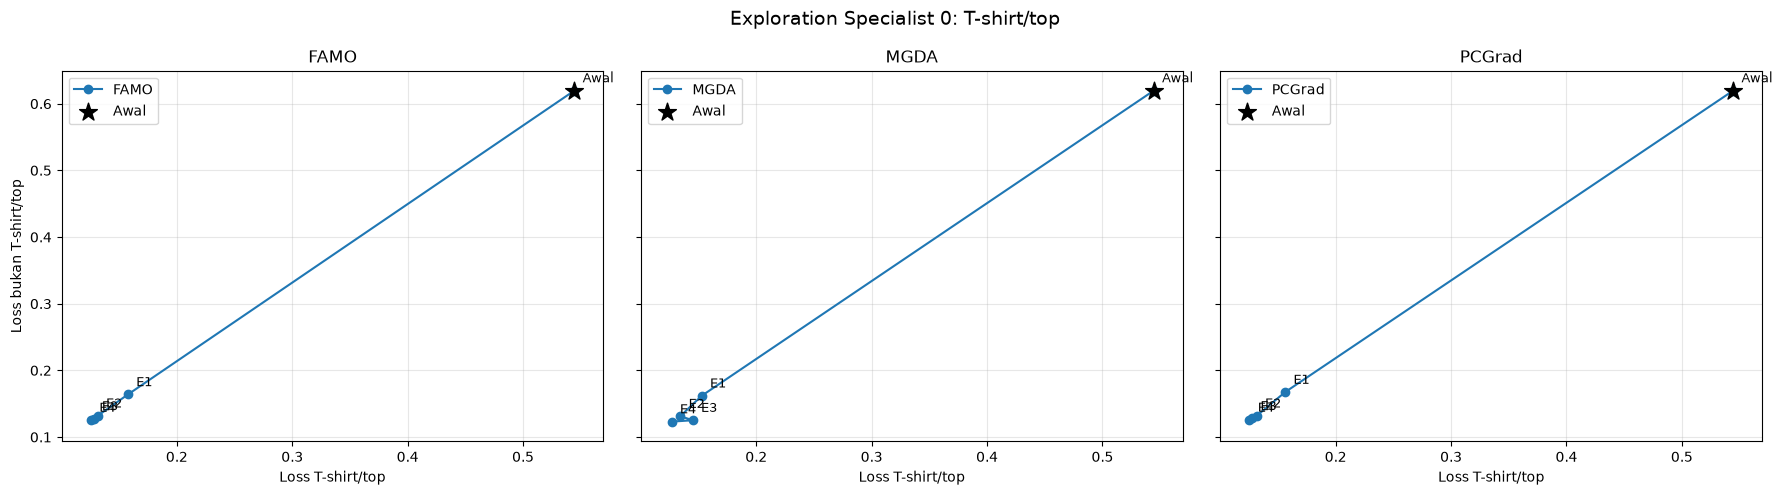

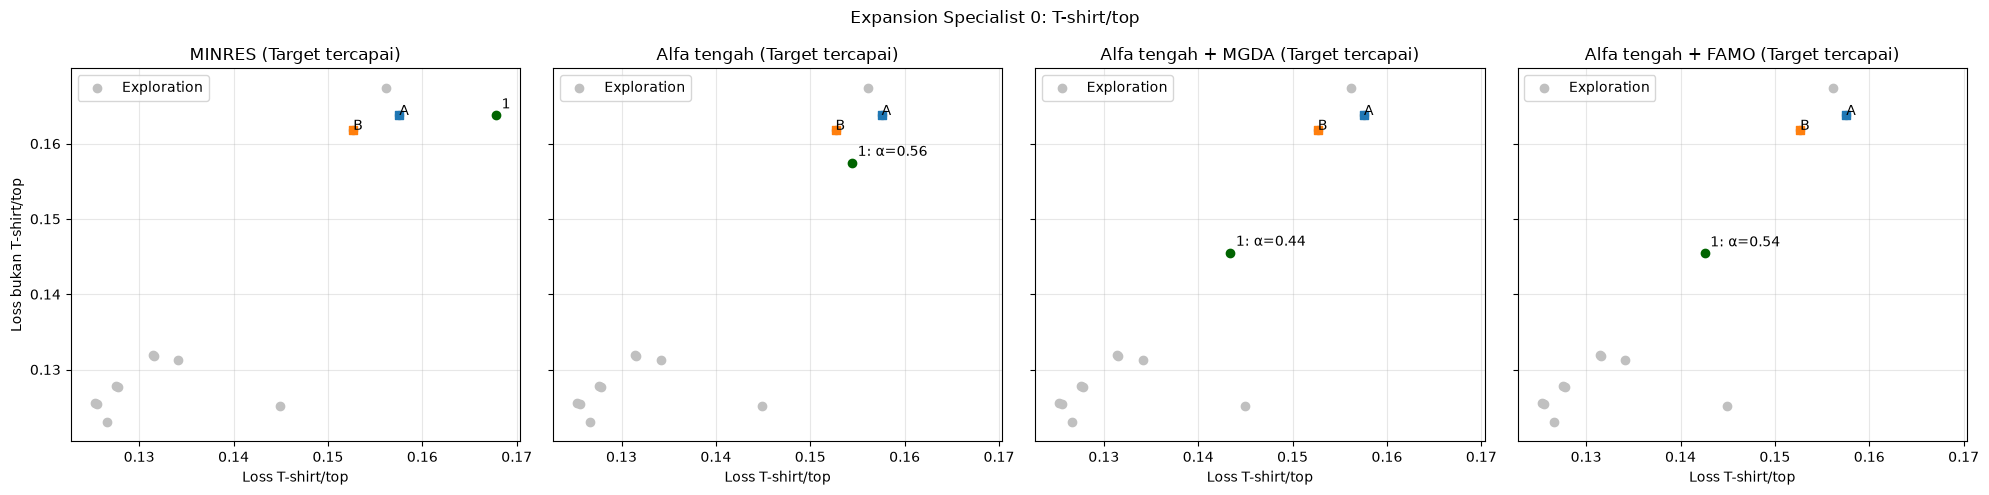

Kandidat nondominated (terhadap semua kandidat validasi):
  MINRES: 0/1 di front
  Alfa tengah: 0/1 di front
  Alfa tengah + MGDA: 0/1 di front
  Alfa tengah + FAMO: 0/1 di front
TERPILIH: PCGrad | valid: [0.1253 0.1255] | test: [0.1221 0.1223]

===== 1/9: Trouser =====
[Trouser] PCGrad epoch 1/4 (434 batch)
    batch 100/434 | 0.4s
    batch 200/434 | 0.7s
    batch 300/434 | 1.1s
    batch 400/434 | 1.5s
    batch 434/434 | 1.6s
    selesai epoch 1: minimax valid=0.07782
[Trouser] PCGrad epoch 2/4 (434 batch)
    batch 100/434 | 0.4s
    batch 200/434 | 0.7s
    batch 300/434 | 1.1s
    batch 400/434 | 1.5s
    batch 434/434 | 1.6s
    selesai epoch 2: minimax valid=0.06491
[Trouser] PCGrad epoch 3/4 (434 batch)
    batch 100/434 | 0.4s
    batch 200/434 | 0.7s
    batch 300/434 | 1.1s
    batch 400/434 | 1.4s
    batch 434/434 | 1.6s
    selesai epoch 3: minimax valid=0.05926
[Trouser] PCGrad epoch 4/4 (434 batch)
    batch 100/434 | 0.4s
    batch 200/434 | 0.7s
    batch 300/434 |

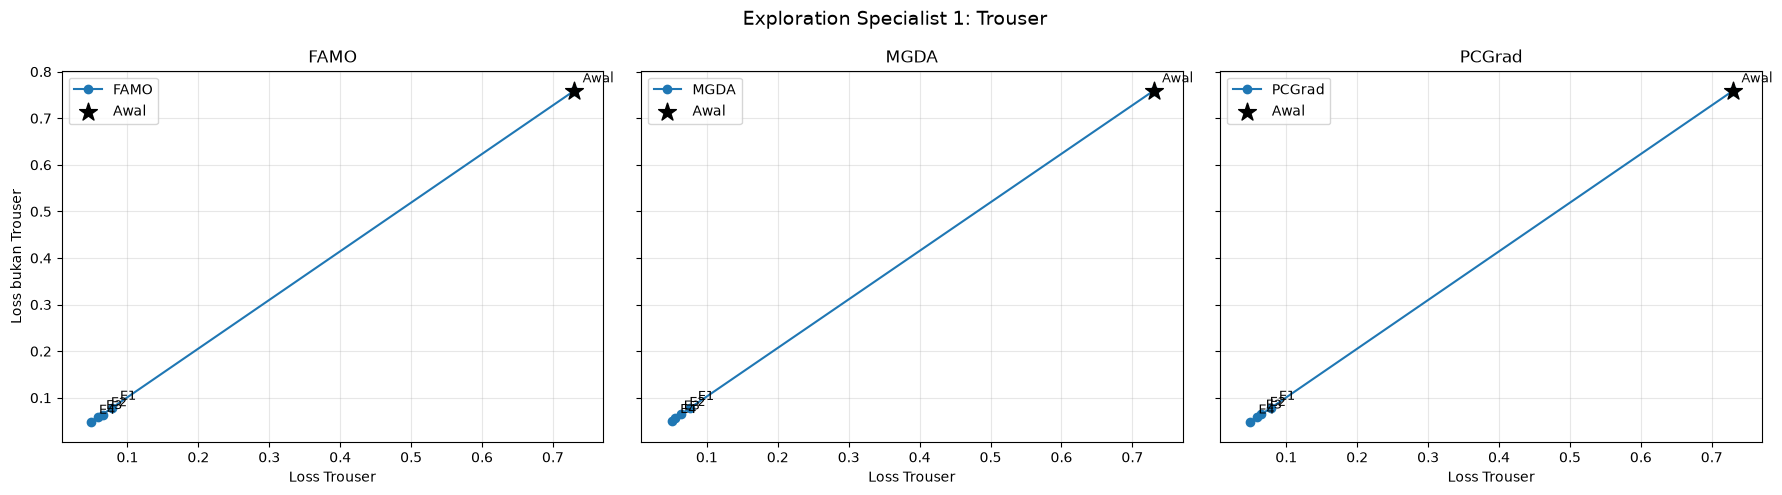

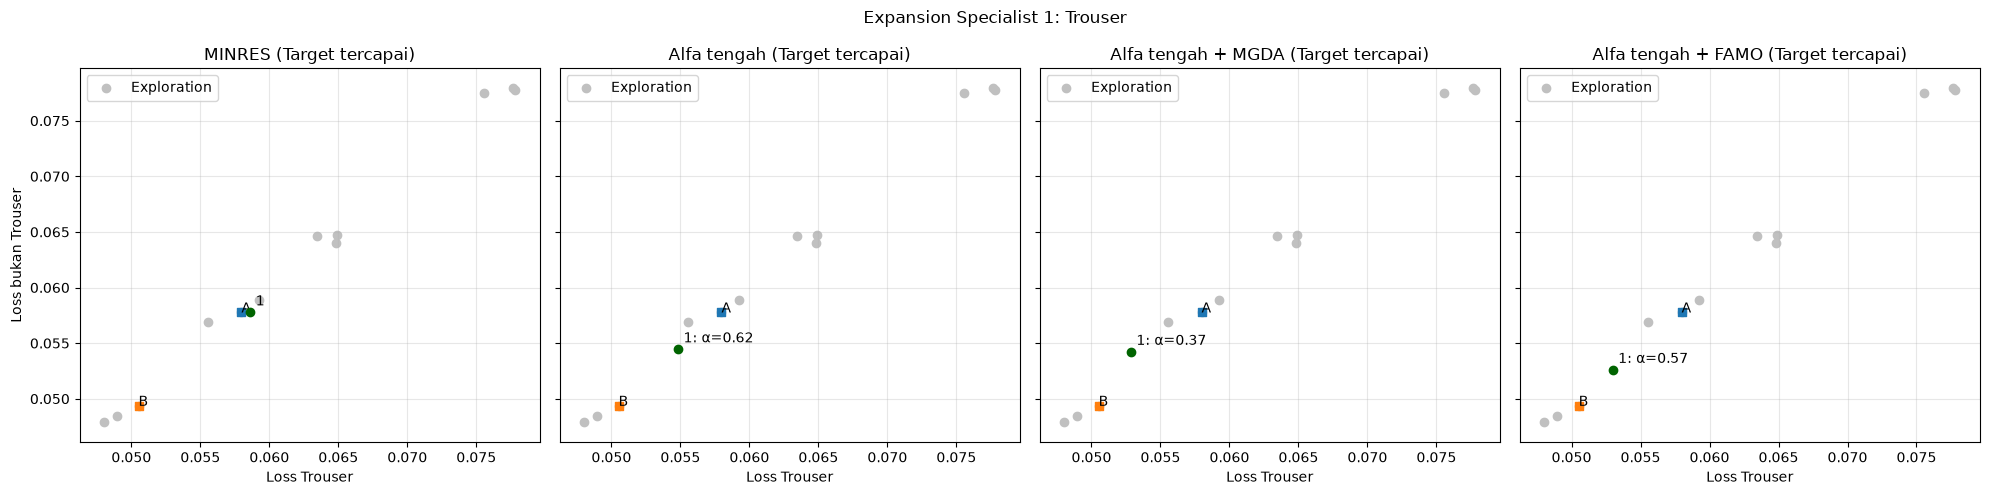

Kandidat nondominated (terhadap semua kandidat validasi):
  MINRES: 0/1 di front
  Alfa tengah: 0/1 di front
  Alfa tengah + MGDA: 0/1 di front
  Alfa tengah + FAMO: 0/1 di front
TERPILIH: FAMO | valid: [0.048  0.0479] | test: [0.0522 0.052 ]

===== 2/9: Pullover =====
[Pullover] PCGrad epoch 1/4 (434 batch)
    batch 100/434 | 0.4s
    batch 200/434 | 0.8s
    batch 300/434 | 1.1s
    batch 400/434 | 1.5s
    batch 434/434 | 1.6s
    selesai epoch 1: minimax valid=0.26668
[Pullover] PCGrad epoch 2/4 (434 batch)
    batch 100/434 | 0.4s
    batch 200/434 | 0.7s
    batch 300/434 | 1.1s
    batch 400/434 | 1.4s
    batch 434/434 | 1.5s
    selesai epoch 2: minimax valid=0.19990
[Pullover] PCGrad epoch 3/4 (434 batch)
    batch 100/434 | 0.4s
    batch 200/434 | 0.7s
    batch 300/434 | 1.1s
    batch 400/434 | 1.4s
    batch 434/434 | 1.5s
    selesai epoch 3: minimax valid=0.18768
[Pullover] PCGrad epoch 4/4 (434 batch)
    batch 100/434 | 0.3s
    batch 200/434 | 0.7s
    batch 300/43

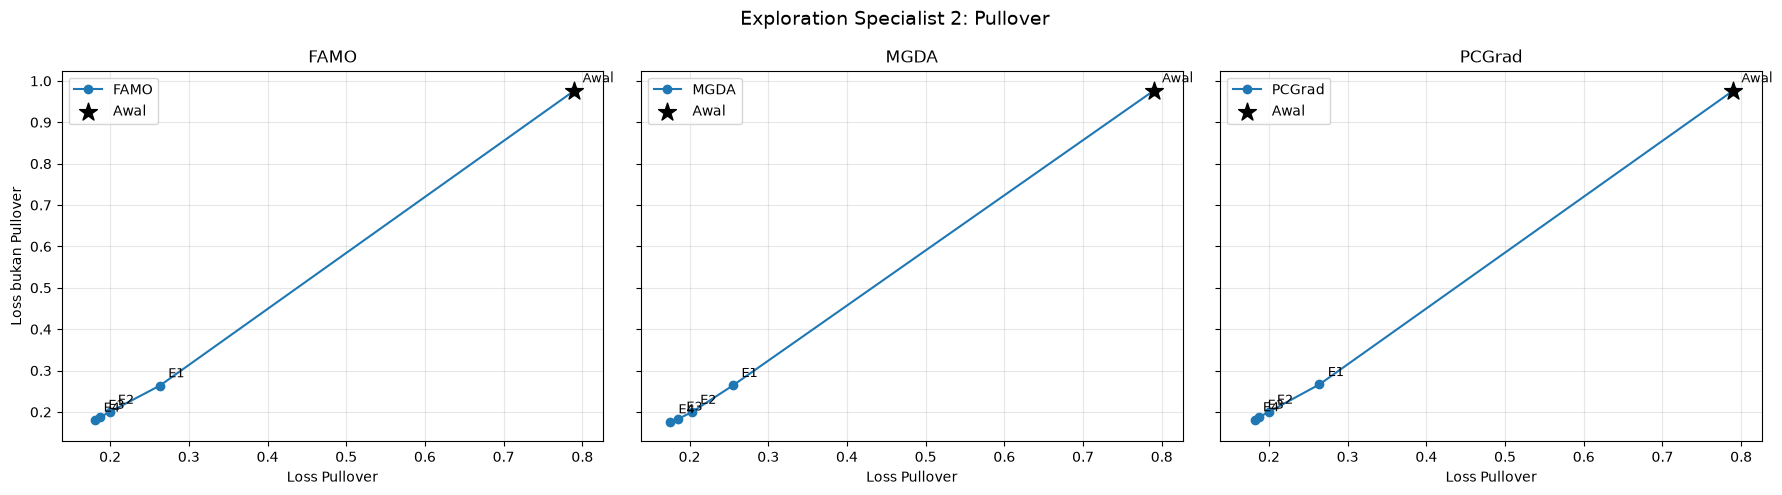

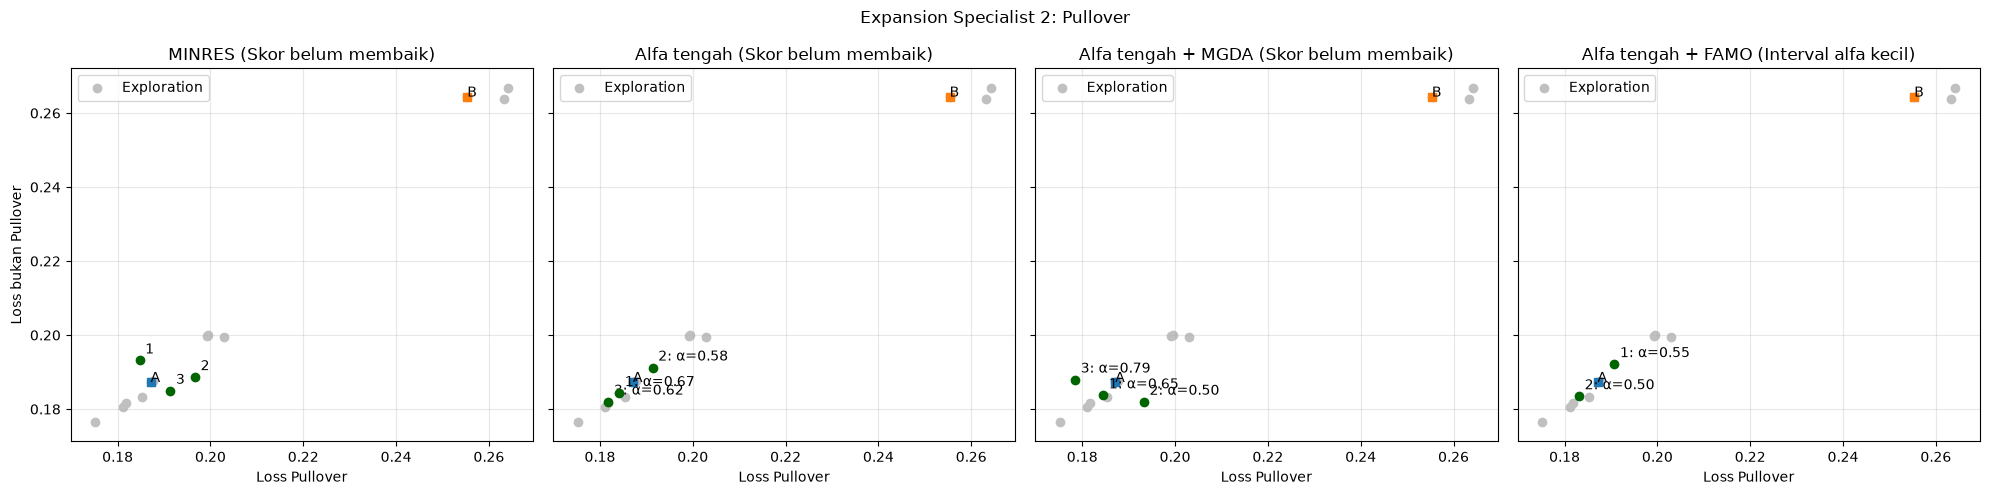

Kandidat nondominated (terhadap semua kandidat validasi):
  MINRES: 0/3 di front
  Alfa tengah: 0/3 di front
  Alfa tengah + MGDA: 0/3 di front
  Alfa tengah + FAMO: 0/2 di front
TERPILIH: MGDA | valid: [0.1752 0.1766] | test: [0.1696 0.1714]

===== 3/9: Dress =====
[Dress] PCGrad epoch 1/4 (434 batch)
    batch 100/434 | 0.4s
    batch 200/434 | 0.7s
    batch 300/434 | 1.1s
    batch 400/434 | 1.4s
    batch 434/434 | 1.6s
    selesai epoch 1: minimax valid=0.17818
[Dress] PCGrad epoch 2/4 (434 batch)
    batch 100/434 | 0.3s
    batch 200/434 | 0.7s
    batch 300/434 | 1.0s
    batch 400/434 | 1.4s
    batch 434/434 | 1.6s
    selesai epoch 2: minimax valid=0.14689
[Dress] PCGrad epoch 3/4 (434 batch)
    batch 100/434 | 0.4s
    batch 200/434 | 0.7s
    batch 300/434 | 1.1s
    batch 400/434 | 1.5s
    batch 434/434 | 1.6s
    selesai epoch 3: minimax valid=0.13667
[Dress] PCGrad epoch 4/4 (434 batch)
    batch 100/434 | 0.4s
    batch 200/434 | 0.7s
    batch 300/434 | 1.1s
    ba

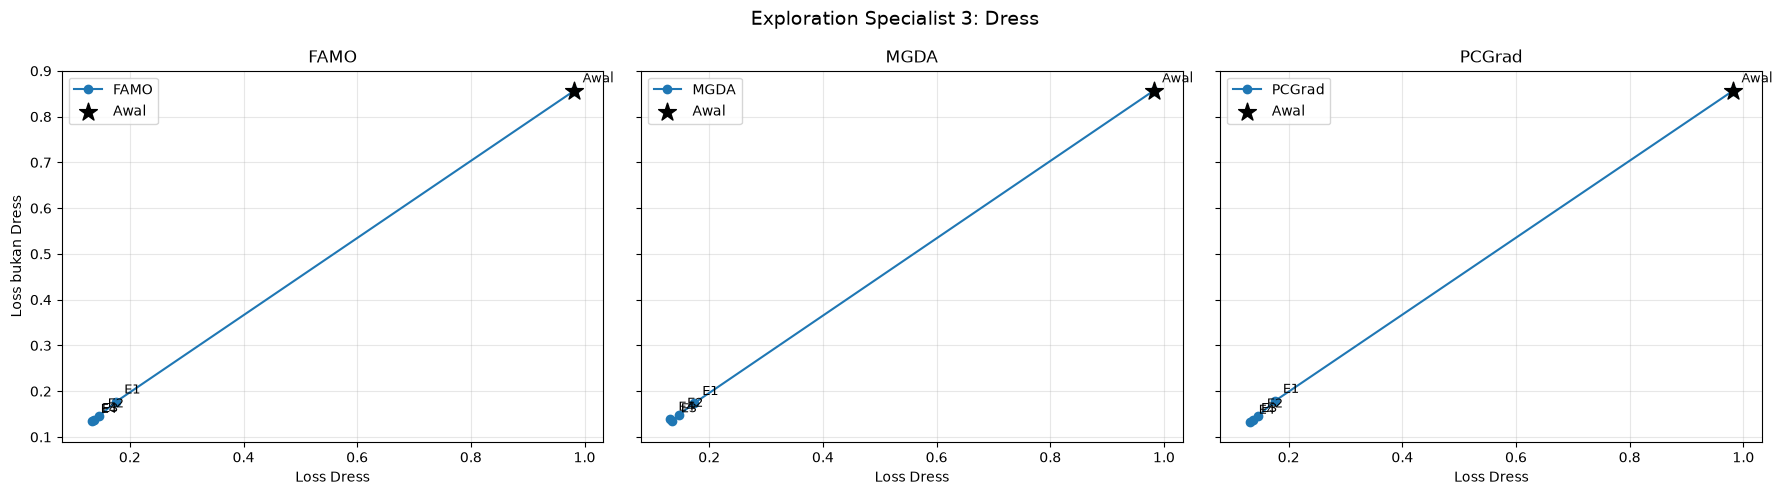

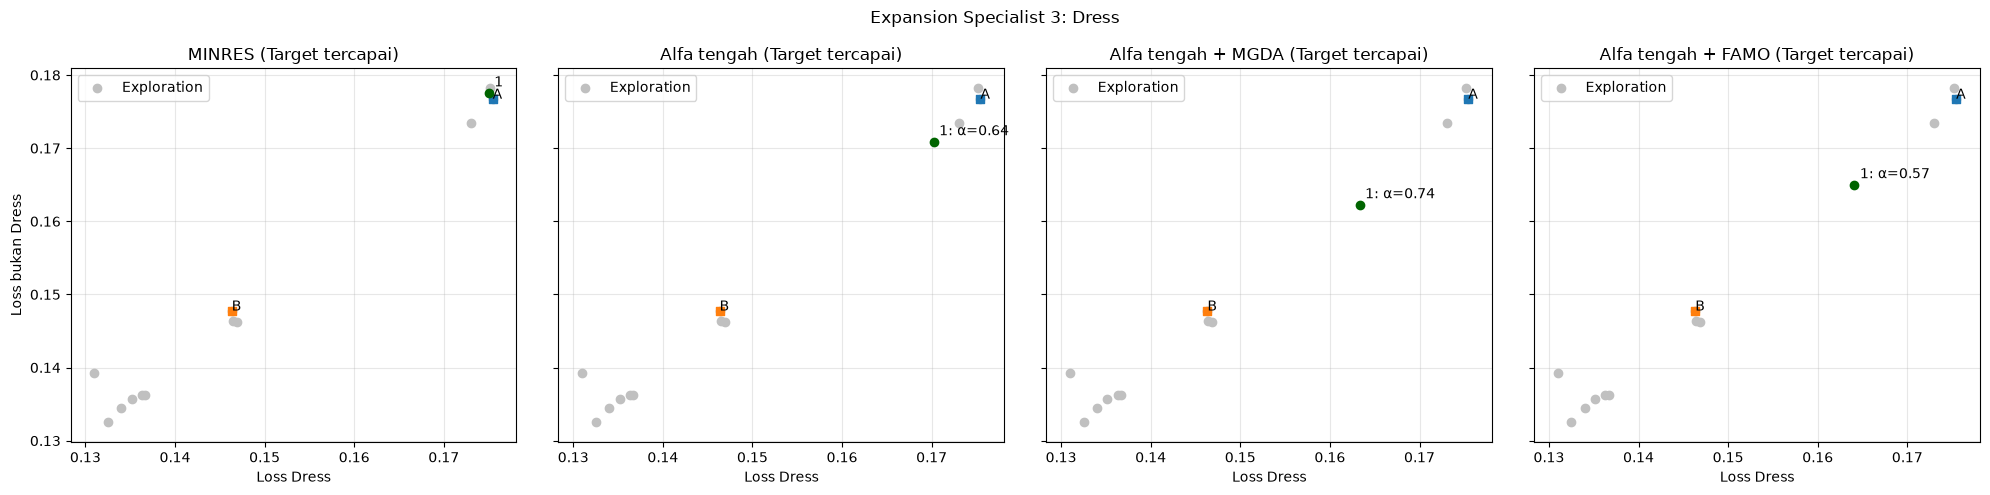

Kandidat nondominated (terhadap semua kandidat validasi):
  MINRES: 0/1 di front
  Alfa tengah: 0/1 di front
  Alfa tengah + MGDA: 0/1 di front
  Alfa tengah + FAMO: 0/1 di front
TERPILIH: PCGrad | valid: [0.1325 0.1326] | test: [0.1444 0.1445]

===== 4/9: Coat =====
[Coat] PCGrad epoch 1/4 (434 batch)
    batch 100/434 | 0.4s
    batch 200/434 | 0.7s
    batch 300/434 | 1.1s
    batch 400/434 | 1.5s
    batch 434/434 | 1.6s
    selesai epoch 1: minimax valid=0.26323
[Coat] PCGrad epoch 2/4 (434 batch)
    batch 100/434 | 0.4s
    batch 200/434 | 0.7s
    batch 300/434 | 1.1s
    batch 400/434 | 1.5s
    batch 434/434 | 1.6s
    selesai epoch 2: minimax valid=0.18338
[Coat] PCGrad epoch 3/4 (434 batch)
    batch 100/434 | 0.3s
    batch 200/434 | 0.7s
    batch 300/434 | 1.1s
    batch 400/434 | 1.5s
    batch 434/434 | 1.6s
    selesai epoch 3: minimax valid=0.16345
[Coat] PCGrad epoch 4/4 (434 batch)
    batch 100/434 | 0.3s
    batch 200/434 | 0.7s
    batch 300/434 | 1.1s
    batch

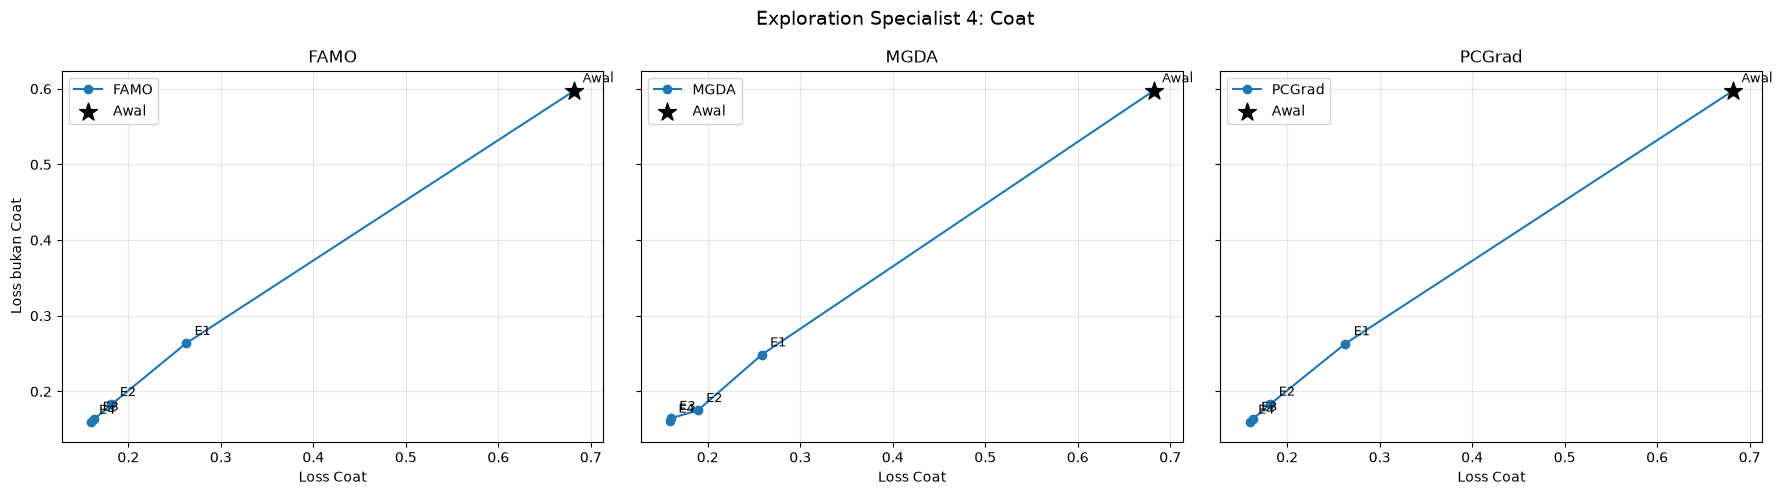

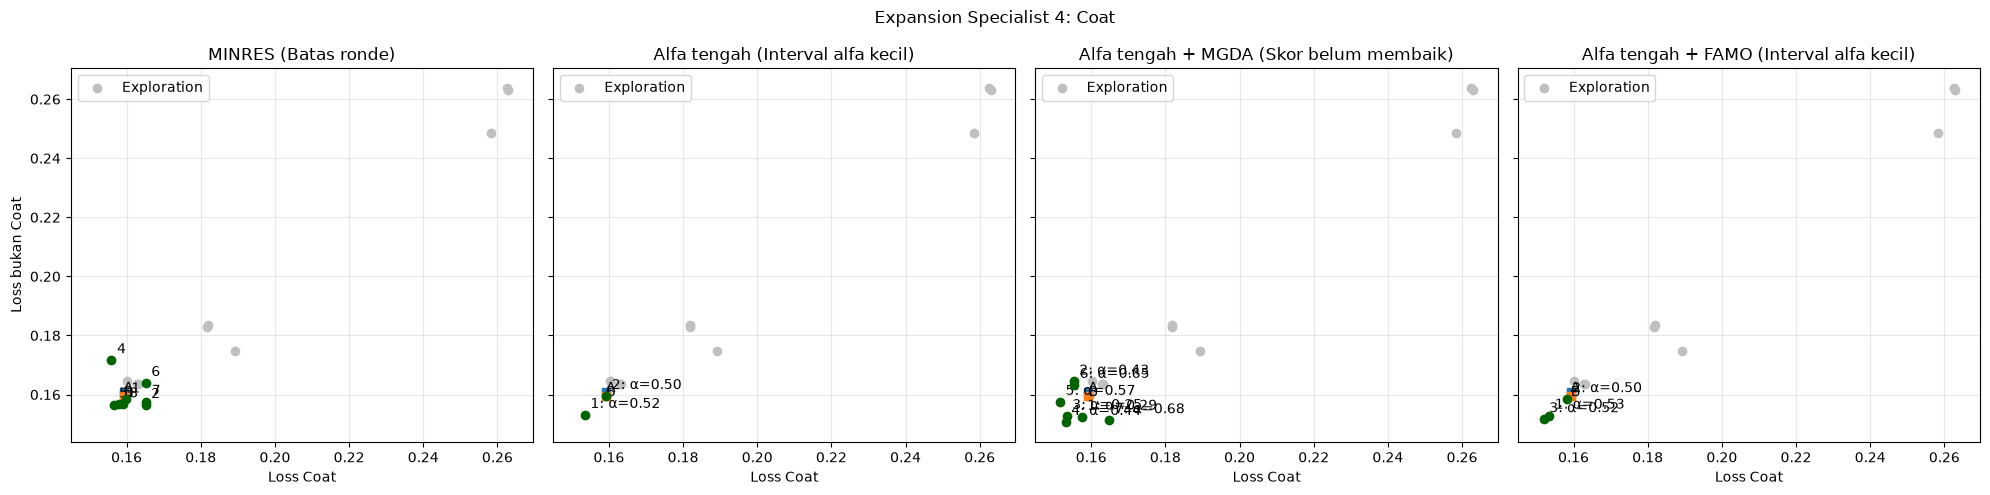

Kandidat nondominated (terhadap semua kandidat validasi):
  MINRES: 0/8 di front
  Alfa tengah: 0/2 di front
  Alfa tengah + MGDA: 2/7 di front
  Alfa tengah + FAMO: 1/3 di front
TERPILIH: Alfa tengah + FAMO | valid: [0.1519 0.1517] | test: [0.1551 0.1549]

===== 5/9: Sandal =====
[Sandal] PCGrad epoch 1/4 (434 batch)
    batch 100/434 | 0.4s
    batch 200/434 | 0.8s
    batch 300/434 | 1.1s
    batch 400/434 | 1.5s
    batch 434/434 | 1.6s
    selesai epoch 1: minimax valid=0.14470
[Sandal] PCGrad epoch 2/4 (434 batch)
    batch 100/434 | 0.3s
    batch 200/434 | 0.7s
    batch 300/434 | 1.0s
    batch 400/434 | 1.4s
    batch 434/434 | 1.5s
    selesai epoch 2: minimax valid=0.13028
[Sandal] PCGrad epoch 3/4 (434 batch)
    batch 100/434 | 0.4s
    batch 200/434 | 0.7s
    batch 300/434 | 1.1s
    batch 400/434 | 1.4s
    batch 434/434 | 1.5s
    selesai epoch 3: minimax valid=0.11397
[Sandal] PCGrad epoch 4/4 (434 batch)
    batch 100/434 | 0.4s
    batch 200/434 | 0.7s
    batch 30

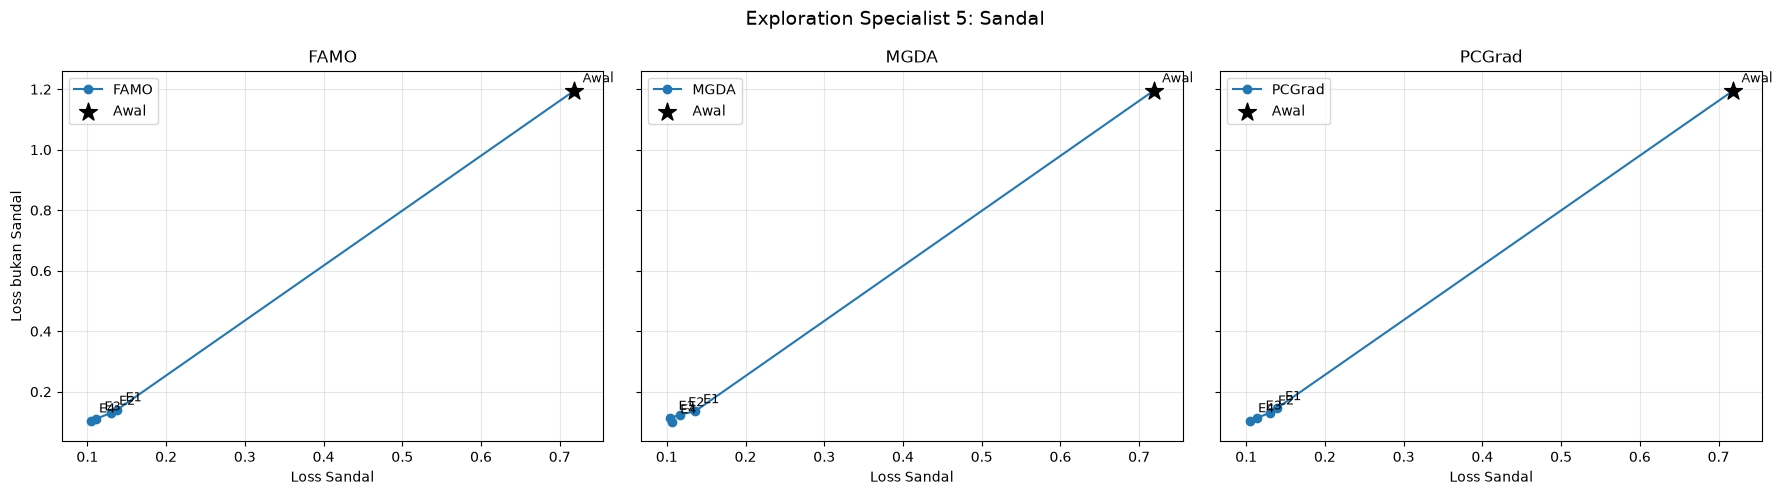

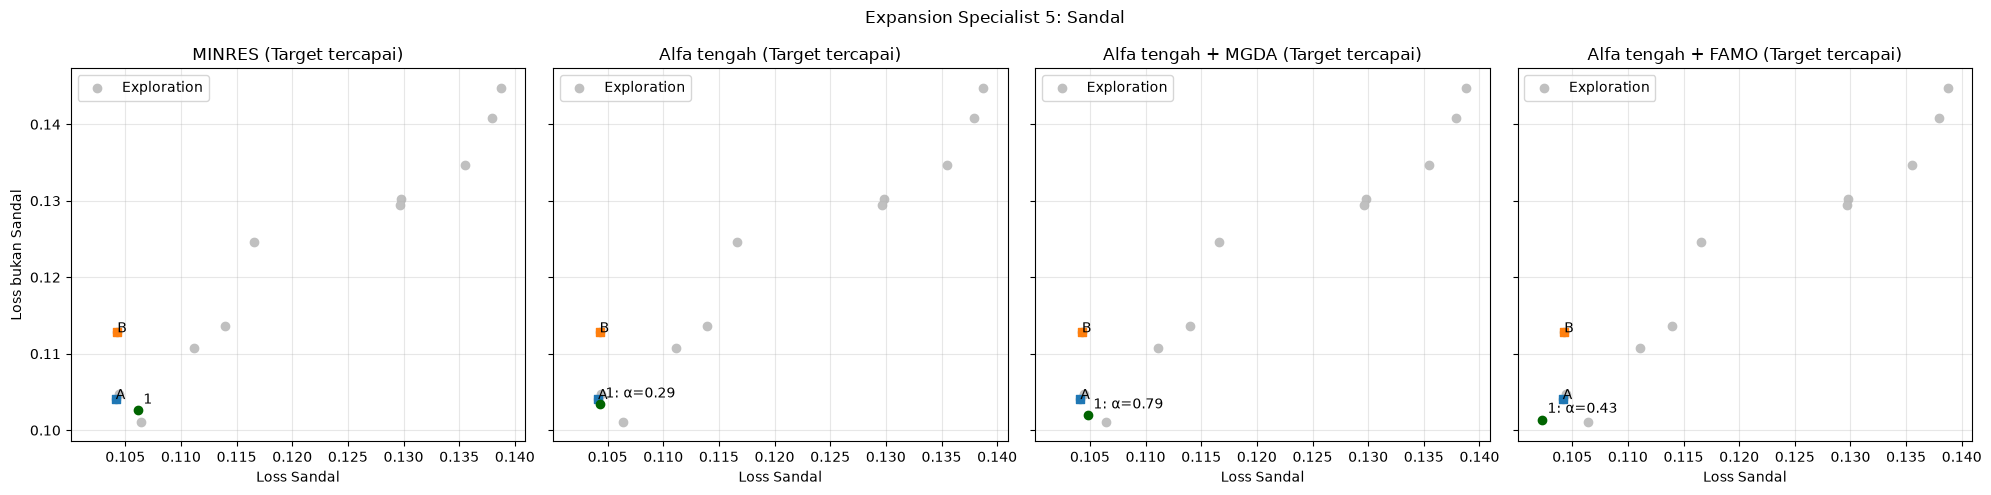

Kandidat nondominated (terhadap semua kandidat validasi):
  MINRES: 0/1 di front
  Alfa tengah: 0/1 di front
  Alfa tengah + MGDA: 0/1 di front
  Alfa tengah + FAMO: 1/1 di front
TERPILIH: Alfa tengah + FAMO | valid: [0.1023 0.1014] | test: [0.0987 0.0977]

===== 6/9: Shirt =====
[Shirt] PCGrad epoch 1/4 (434 batch)
    batch 100/434 | 0.4s
    batch 200/434 | 0.7s
    batch 300/434 | 1.1s
    batch 400/434 | 1.4s
    batch 434/434 | 1.6s
    selesai epoch 1: minimax valid=0.31343
[Shirt] PCGrad epoch 2/4 (434 batch)
    batch 100/434 | 0.3s
    batch 200/434 | 0.7s
    batch 300/434 | 1.0s
    batch 400/434 | 1.4s
    batch 434/434 | 1.5s
    selesai epoch 2: minimax valid=0.26923
[Shirt] PCGrad epoch 3/4 (434 batch)
    batch 100/434 | 0.3s
    batch 200/434 | 0.7s
    batch 300/434 | 1.0s
    batch 400/434 | 1.3s
    batch 434/434 | 1.5s
    selesai epoch 3: minimax valid=0.25421
[Shirt] PCGrad epoch 4/4 (434 batch)
    batch 100/434 | 0.4s
    batch 200/434 | 0.7s
    batch 300/434

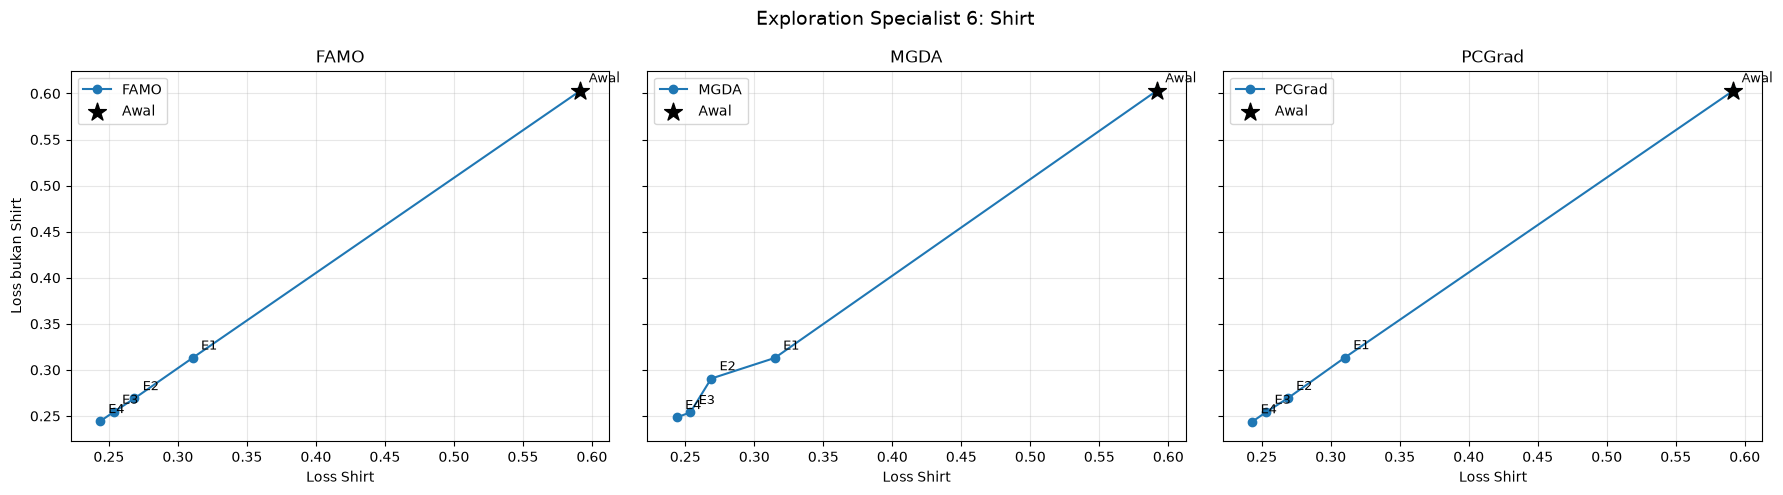

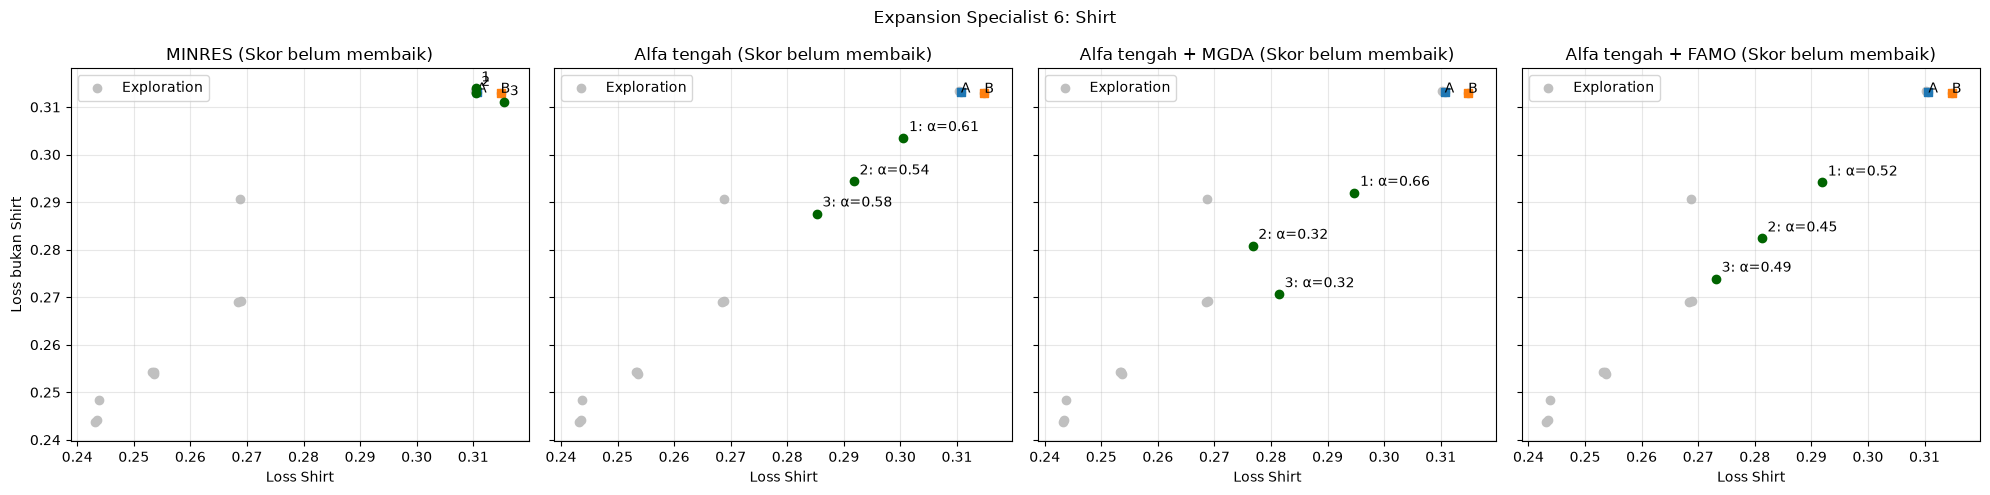

Kandidat nondominated (terhadap semua kandidat validasi):
  MINRES: 0/3 di front
  Alfa tengah: 0/3 di front
  Alfa tengah + MGDA: 0/3 di front
  Alfa tengah + FAMO: 0/3 di front
TERPILIH: PCGrad | valid: [0.2432 0.2438] | test: [0.2403 0.2409]

===== 7/9: Sneaker =====
[Sneaker] PCGrad epoch 1/4 (434 batch)
    batch 100/434 | 0.4s
    batch 200/434 | 0.7s
    batch 300/434 | 1.1s
    batch 400/434 | 1.5s
    batch 434/434 | 1.6s
    selesai epoch 1: minimax valid=0.12437
[Sneaker] PCGrad epoch 2/4 (434 batch)
    batch 100/434 | 0.4s
    batch 200/434 | 0.7s
    batch 300/434 | 1.1s
    batch 400/434 | 1.4s
    batch 434/434 | 1.5s
    selesai epoch 2: minimax valid=0.11161
[Sneaker] PCGrad epoch 3/4 (434 batch)
    batch 100/434 | 0.3s
    batch 200/434 | 0.7s
    batch 300/434 | 1.1s
    batch 400/434 | 1.4s
    batch 434/434 | 1.5s
    selesai epoch 3: minimax valid=0.10269
[Sneaker] PCGrad epoch 4/4 (434 batch)
    batch 100/434 | 0.4s
    batch 200/434 | 0.7s
    batch 300/434 |

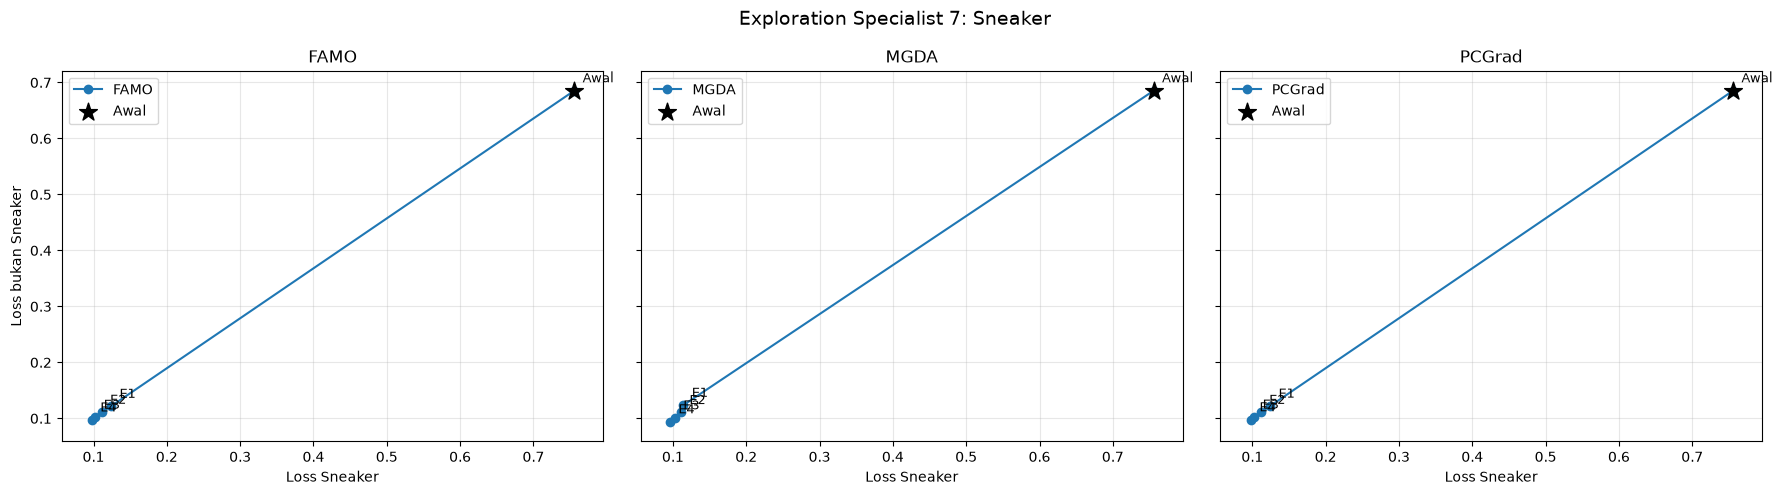

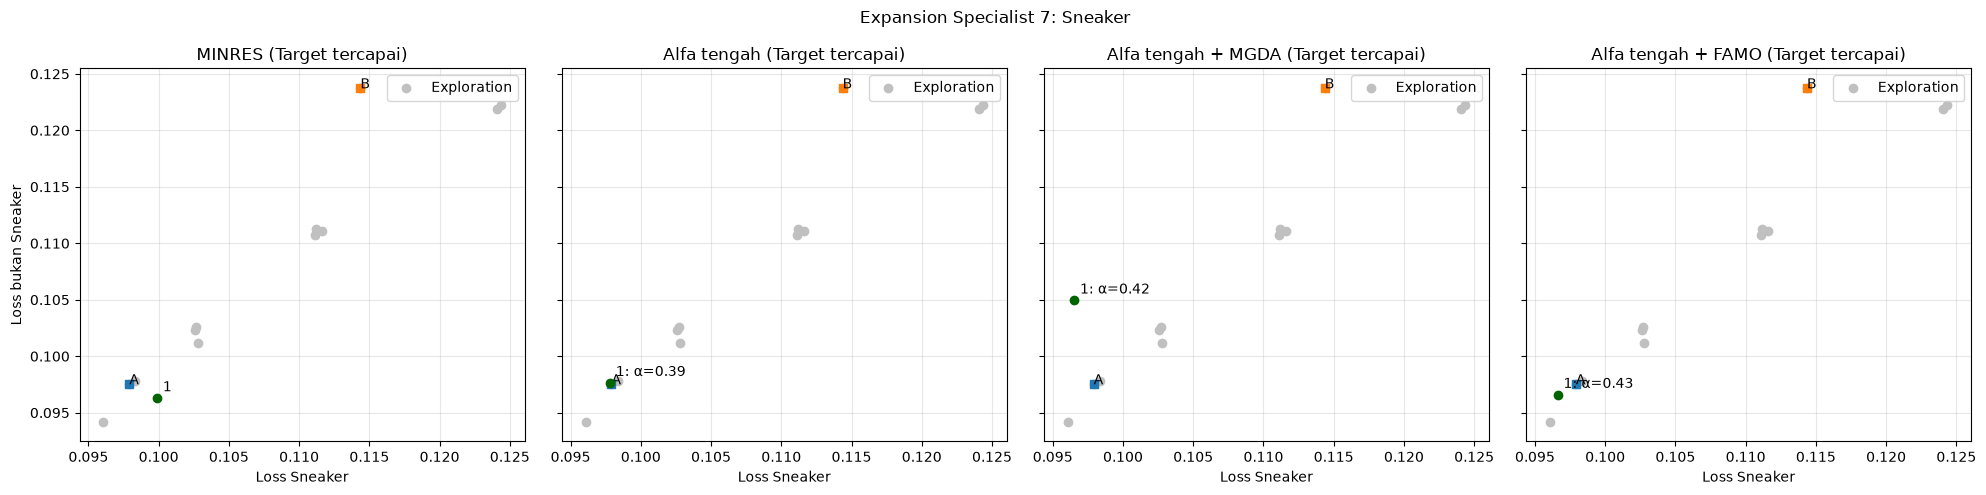

Kandidat nondominated (terhadap semua kandidat validasi):
  MINRES: 0/1 di front
  Alfa tengah: 0/1 di front
  Alfa tengah + MGDA: 0/1 di front
  Alfa tengah + FAMO: 0/1 di front
TERPILIH: MGDA | valid: [0.0961 0.0942] | test: [0.0839 0.0829]

===== 8/9: Bag =====
[Bag] PCGrad epoch 1/4 (434 batch)
    batch 100/434 | 0.4s
    batch 200/434 | 0.7s
    batch 300/434 | 1.1s
    batch 400/434 | 1.4s
    batch 434/434 | 1.6s
    selesai epoch 1: minimax valid=0.15543
[Bag] PCGrad epoch 2/4 (434 batch)
    batch 100/434 | 0.4s
    batch 200/434 | 0.7s
    batch 300/434 | 1.0s
    batch 400/434 | 1.4s
    batch 434/434 | 1.5s
    selesai epoch 2: minimax valid=0.09000
[Bag] PCGrad epoch 3/4 (434 batch)
    batch 100/434 | 0.3s
    batch 200/434 | 0.7s
    batch 300/434 | 1.0s
    batch 400/434 | 1.4s
    batch 434/434 | 1.5s
    selesai epoch 3: minimax valid=0.07353
[Bag] PCGrad epoch 4/4 (434 batch)
    batch 100/434 | 0.3s
    batch 200/434 | 0.7s
    batch 300/434 | 1.0s
    batch 400/43

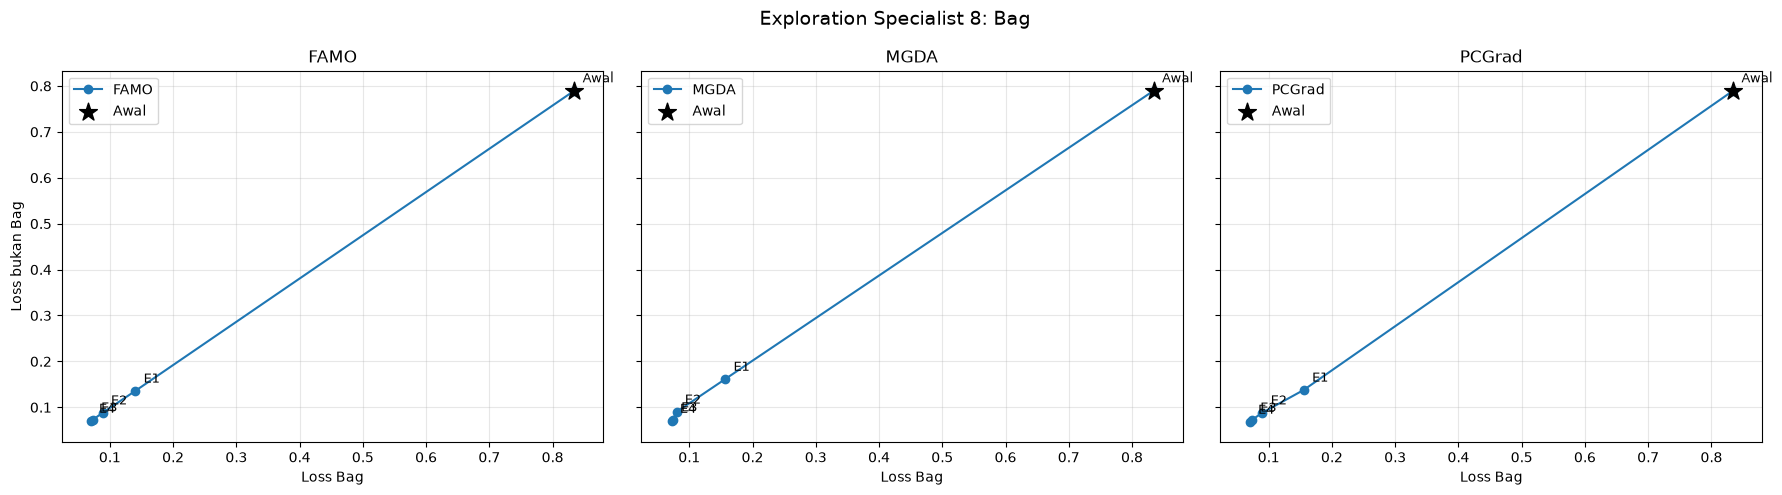

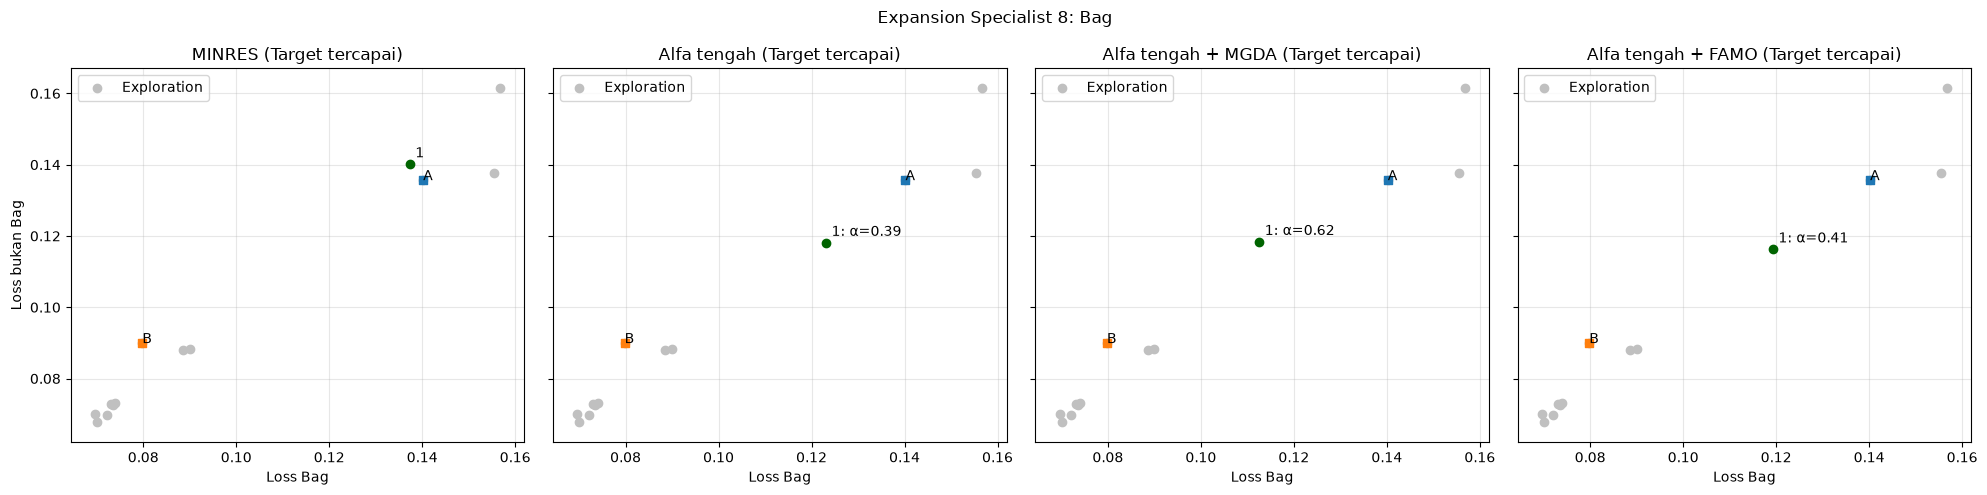

Kandidat nondominated (terhadap semua kandidat validasi):
  MINRES: 0/1 di front
  Alfa tengah: 0/1 di front
  Alfa tengah + MGDA: 0/1 di front
  Alfa tengah + FAMO: 0/1 di front
TERPILIH: FAMO | valid: [0.0696 0.07  ] | test: [0.0652 0.0653]

===== 9/9: Ankle boot =====
[Ankle boot] PCGrad epoch 1/4 (434 batch)
    batch 100/434 | 0.4s
    batch 200/434 | 0.7s
    batch 300/434 | 1.1s
    batch 400/434 | 1.4s
    batch 434/434 | 1.5s
    selesai epoch 1: minimax valid=0.06581
[Ankle boot] PCGrad epoch 2/4 (434 batch)
    batch 100/434 | 0.4s
    batch 200/434 | 0.7s
    batch 300/434 | 1.1s
    batch 400/434 | 1.4s
    batch 434/434 | 1.6s
    selesai epoch 2: minimax valid=0.06144
[Ankle boot] PCGrad epoch 3/4 (434 batch)
    batch 100/434 | 0.4s
    batch 200/434 | 0.7s
    batch 300/434 | 1.0s
    batch 400/434 | 1.4s
    batch 434/434 | 1.5s
    selesai epoch 3: minimax valid=0.05733
[Ankle boot] PCGrad epoch 4/4 (434 batch)
    batch 100/434 | 0.3s
    batch 200/434 | 0.7s
    ba

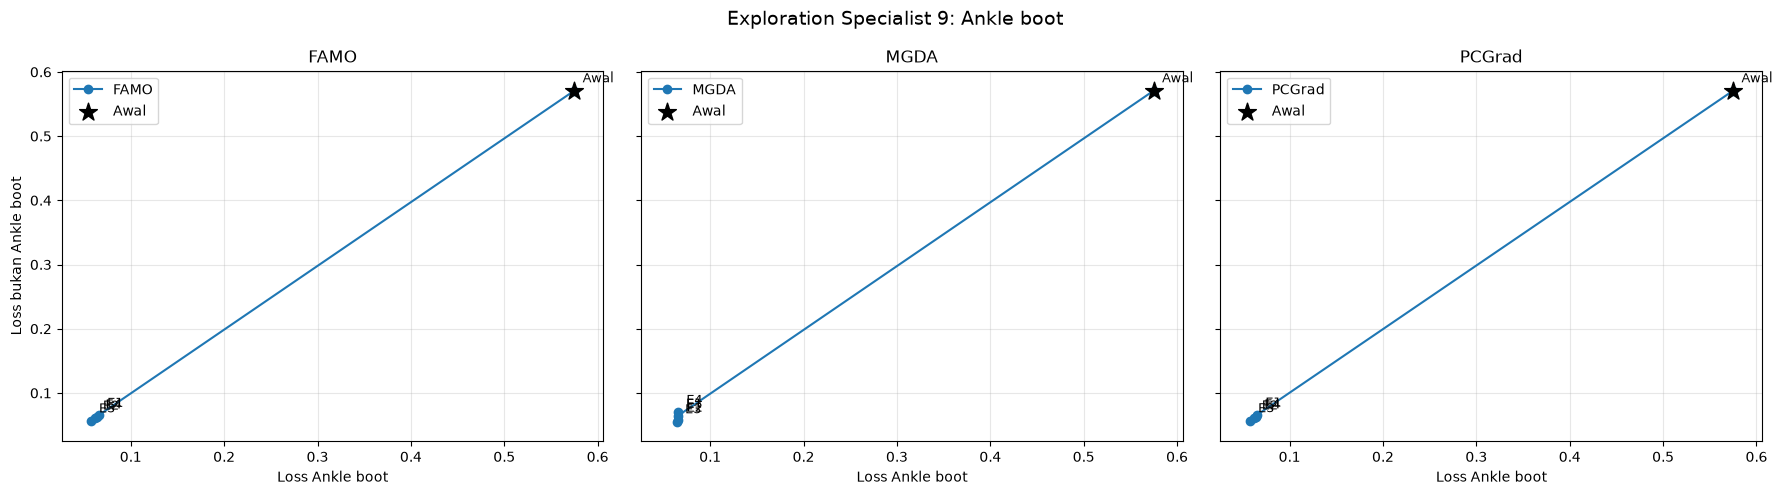

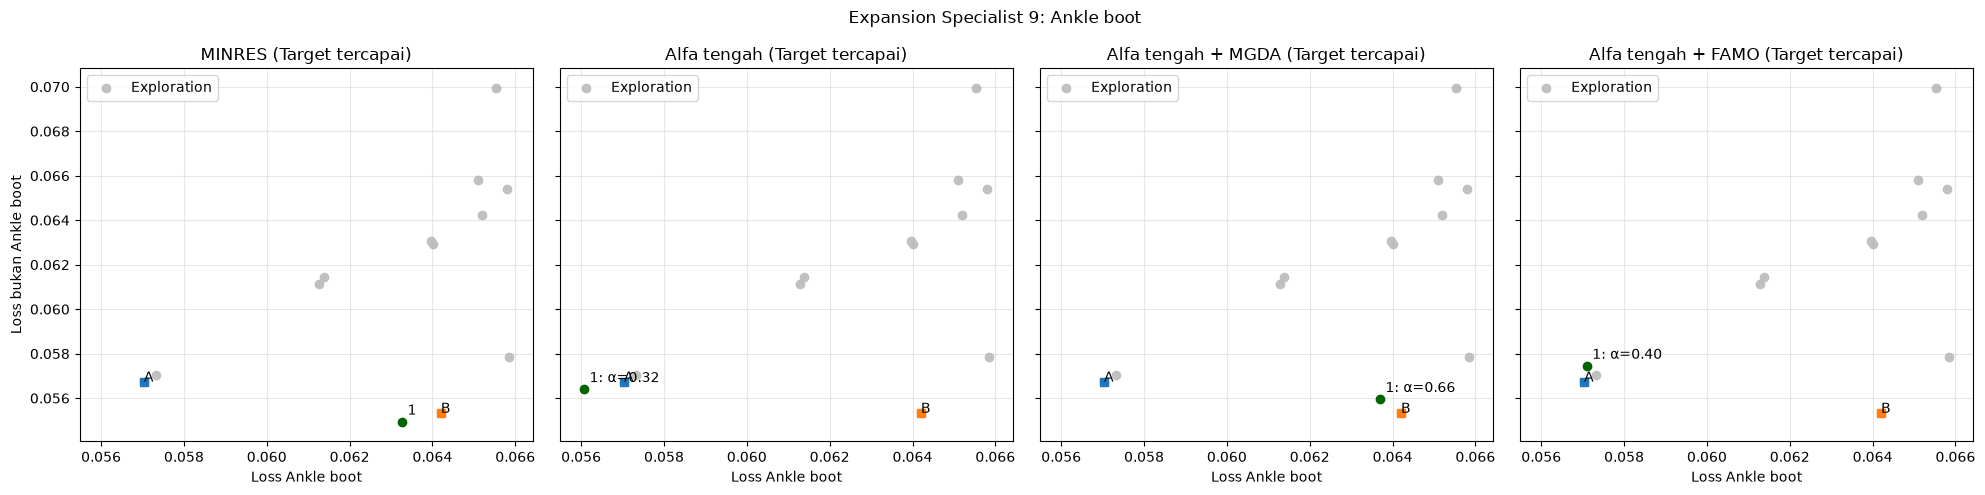

Kandidat nondominated (terhadap semua kandidat validasi):
  MINRES: 1/1 di front
  Alfa tengah: 1/1 di front
  Alfa tengah + MGDA: 0/1 di front
  Alfa tengah + FAMO: 0/1 di front
TERPILIH: Alfa tengah | valid: [0.0561 0.0564] | test: [0.058  0.0583]
Selesai: seluruh 10 teacher dibuat dari hasil Pareto Exploration/Expansion.


In [33]:
# Sel training yang panjang: 10 kelas × 3 metode exploration × 2 metode expansion.
teachers = []
specialist_summaries = []
for class_id in range(len(CLASS_NAMES)):
    print(f"\n===== {class_id}/9: {CLASS_NAMES[class_id]} =====")
    teacher, summary = run_specialist_class(class_id)
    teachers.append(teacher)
    specialist_summaries.append(summary)
    print('TERPILIH:', summary['selected_method'],
          '| valid:', np.round(summary['selected_valid'], 4),
          '| test:', np.round(summary['selected_test'], 4))

assert len(teachers) == len(CLASS_NAMES)
print('Selesai: seluruh 10 teacher dibuat dari hasil Pareto Exploration/Expansion.')


In [34]:
# Ringkasan semua metode termasuk midpoint yang di-refine.
print('Kelas | Teacher terpilih | valid minimax | metode expansion: jumlah ronde / front')
for s in specialist_summaries:
    counts = s['pareto_front_counts']
    desc = ' | '.join(
        f"{name}: {info['rounds']}/{counts.get(name, 0)}"
        for name, info in s['expansion'].items() if name != 'Tanpa expand'
    )
    print(f"{s['class_name']:12} | {s['selected_method']:20} | "
          f"{s['selected_score']:.4f} | {desc}")


Kelas | Teacher terpilih | valid minimax | metode expansion: jumlah ronde / front
T-shirt/top  | PCGrad               | 0.1255 | MINRES: 1/0 | Alfa tengah: 1/0 | Alfa tengah + MGDA: 1/0 | Alfa tengah + FAMO: 1/0
Trouser      | FAMO                 | 0.0480 | MINRES: 1/0 | Alfa tengah: 1/0 | Alfa tengah + MGDA: 1/0 | Alfa tengah + FAMO: 1/0
Pullover     | MGDA                 | 0.1766 | MINRES: 3/0 | Alfa tengah: 3/0 | Alfa tengah + MGDA: 3/0 | Alfa tengah + FAMO: 2/0
Dress        | PCGrad               | 0.1326 | MINRES: 1/0 | Alfa tengah: 1/0 | Alfa tengah + MGDA: 1/0 | Alfa tengah + FAMO: 1/0
Coat         | Alfa tengah + FAMO   | 0.1519 | MINRES: 8/0 | Alfa tengah: 2/0 | Alfa tengah + MGDA: 7/2 | Alfa tengah + FAMO: 3/1
Sandal       | Alfa tengah + FAMO   | 0.1023 | MINRES: 1/0 | Alfa tengah: 1/0 | Alfa tengah + MGDA: 1/0 | Alfa tengah + FAMO: 1/1
Shirt        | PCGrad               | 0.2438 | MINRES: 3/0 | Alfa tengah: 3/0 | Alfa tengah + MGDA: 3/0 | Alfa tengah + FAMO: 3/0
Sneaker 

## Generalist CNN: 10 head × 2 logit, **10 objective Pareto**

Generalist melihat **kanvas gabungan penuh**, menggunakan target lunak dari kesepuluh teacher saat training dan label asli saat evaluasi. Setiap kelas memiliki 1 head dengan 2 output (hadir dan tidak hadir), sehingga forward mengembalikan `(B, 10, 2)`.

**Optimasi 10 tugas:** loss tugas kelas *c* = rata-rata BCE *hadir* dan *tidak hadir* untuk kelas *c*. Berbeda dari notebook sebelumnya yang hanya memakai 2 loss agregat semua kelas, kini PCGrad, MGDA, FAMO, MINRES, dan Alfa tengah menggunakan **10 loss terpisah**. `score = max(10 loss validasi)` dan bobot alpha memiliki 10 komponen.

Grafik 2D masih menggunakan **rata-rata loss hadir (X)** dan **rata-rata loss tidak hadir (Y)** hanya untuk visualisasi. Pareto/dominasi serta pemilihan kandidat memakai vektor 10 tujuan, bukan kedua koordinat pada grafik.


In [35]:
class Generalist(Specialist):
    def __init__(self):
        super().__init__()
        # Satu backbone bersama; tiap lapisan menghasilkan dua skor untuk satu kelas.
        self.heads = nn.ModuleList(nn.Linear(32, 2) for _ in CLASS_NAMES)

    def forward(self, x):
        features = self.backbone(x)
        return torch.stack([head(features) for head in self.heads], dim=1)

In [36]:
@torch.no_grad()
def teacher_targets(images, positions, teachers):
    # Satu guru menilai setiap crop yang terisi. Ambil peluang tertinggi antar-crop.
    target = torch.zeros(len(images), len(teachers))
    for slot in range(positions.shape[1]):
        rows = np.flatnonzero(positions[:, slot, 0] >= 0)
        crops = crop_pad(images, positions, slot)
        for start_row in range(0, len(rows), CFG['BS']):
            ids = rows[start_row:start_row + CFG['BS']]
            x = prep(torch.from_numpy(crops[ids]).to(dev))
            prob = torch.stack([t(x)[:, 0].sigmoid() for t in teachers], dim=1).cpu()
            target[ids] = torch.maximum(target[ids], prob)
    return target

In [37]:
def generalist_data(images, labels, size, seed, teachers=None):
    # ID kelas tiap slot menjadi label hadir/tidak untuk evaluasi. Guru memberikan target latih.
    canvas, slots, positions = make_multi_flexible(images, labels, size, seed=seed)
    if teachers is None:
        target = torch.stack([torch.from_numpy((slots == c).any(axis=1))
                              for c in range(len(CLASS_NAMES))], dim=1).float()
    else:
        target = teacher_targets(canvas, positions, teachers)
    return torch.from_numpy(canvas), target

In [38]:
gen_train = generalist_data(fa_tr_x, fa_tr_y, 20000, 1, teachers)
gen_valid = generalist_data(fa_val_x, fa_val_y, 2000, 2)
gen_test = generalist_data(fa_te_x, fa_te_y, 5000, 3)

In [39]:
# Exploration Generalist: setiap metode dari bobot CNN yang sama, 10 objective per kelas.
set_seed(CFG['SEED'])
gen_initial = Generalist().to(dev)
gen_start = checkpoint(gen_initial, 'Awal', valid=gen_valid)
assert gen_start['objectives'].shape == (len(CLASS_NAMES),)
assert gen_initial(prep(gen_train[0][:2].to(dev))).shape == (2, len(CLASS_NAMES), 2)
gen_paths = {
    m: explore(gen_initial, m, gen_train, gen_valid)
    for m in ('PCGrad', 'MGDA', 'FAMO')
}


[Generalis] PCGrad epoch 1/4 (157 batch)
    batch 100/157 | 2.9s
    batch 157/157 | 4.5s
    selesai epoch 1: minimax valid=0.64428
[Generalis] PCGrad epoch 2/4 (157 batch)
    batch 100/157 | 2.9s
    batch 157/157 | 4.5s
    selesai epoch 2: minimax valid=0.64315
[Generalis] PCGrad epoch 3/4 (157 batch)
    batch 100/157 | 2.9s
    batch 157/157 | 4.5s
    selesai epoch 3: minimax valid=0.65703
[Generalis] PCGrad epoch 4/4 (157 batch)
    batch 100/157 | 2.7s
    batch 157/157 | 4.4s
    selesai epoch 4: minimax valid=0.65573
[Generalis] MGDA epoch 1/4 (157 batch)
    batch 100/157 | 3.1s
    batch 157/157 | 4.9s
    selesai epoch 1: minimax valid=0.64653
[Generalis] MGDA epoch 2/4 (157 batch)
    batch 100/157 | 3.0s
    batch 157/157 | 4.7s
    selesai epoch 2: minimax valid=0.62786
[Generalis] MGDA epoch 3/4 (157 batch)
    batch 100/157 | 3.0s
    batch 157/157 | 4.6s
    selesai epoch 3: minimax valid=0.65233
[Generalis] MGDA epoch 4/4 (157 batch)
    batch 100/157 | 3.0s
    

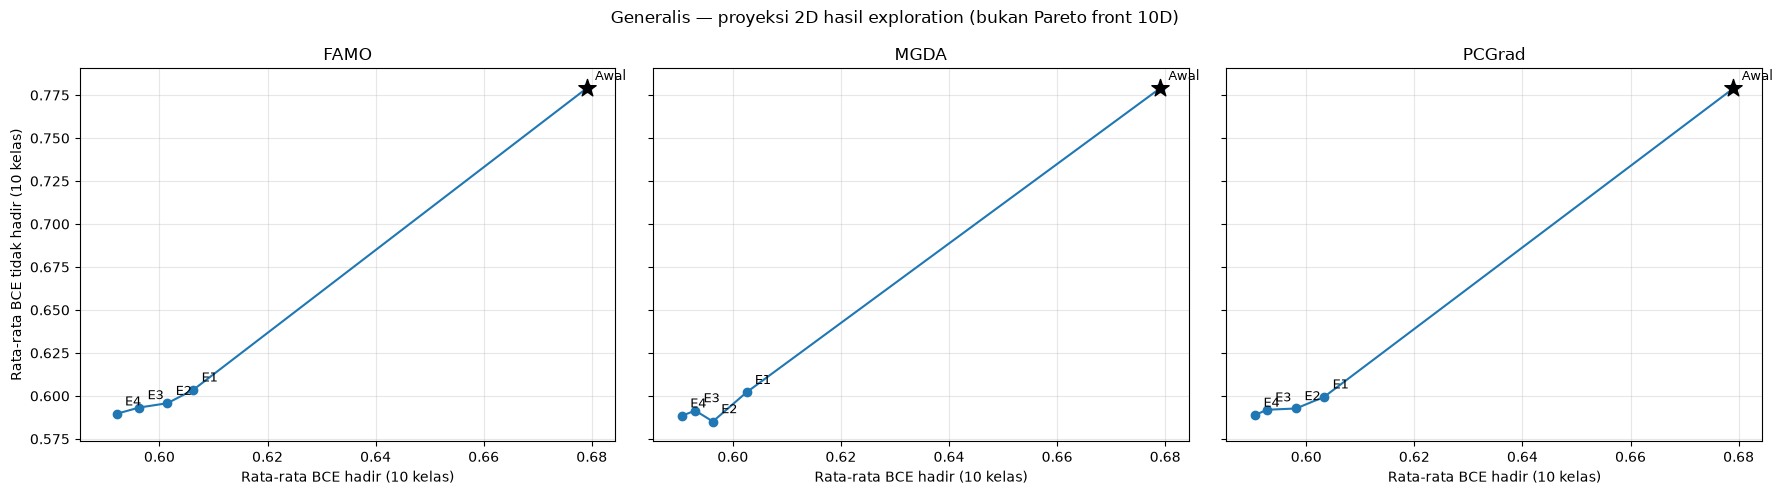

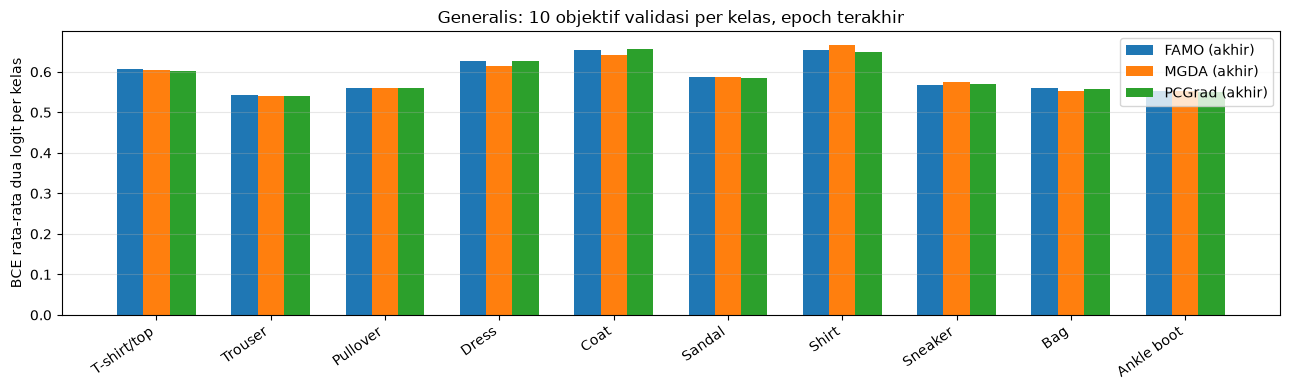

In [40]:
# Perbandingan apple-to-apple: 3 panel skala sama (proyeksi 2D dari 10 objektif).
methods = ('FAMO', 'MGDA', 'PCGrad')
all_xy = np.vstack([
    np.array([cp['xy'] for cp in [gen_start] + gen_paths[m]])
    for m in methods
])
lo, hi = all_xy.min(axis=0), all_xy.max(axis=0)
margin = np.maximum((hi - lo) * 0.06, 1e-4)
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharex=True, sharey=True)
for ax, method in zip(axes, methods):
    points = [gen_start] + gen_paths[method]
    xy = np.array([cp['xy'] for cp in points])
    ax.plot(xy[:, 0], xy[:, 1], 'o-', label=method)
    ax.scatter(*gen_start['xy'], marker='*', color='black', s=170, zorder=5)
    for ep, coordinates in enumerate(xy):
        ax.annotate('Awal' if ep == 0 else f'E{ep}', coordinates,
                    xytext=(6, 6), textcoords='offset points', fontsize=9)
    ax.set(xlim=(lo[0]-margin[0], hi[0]+margin[0]),
           ylim=(lo[1]-margin[1], hi[1]+margin[1]),
           title=method, xlabel='Rata-rata BCE hadir (10 kelas)')
    ax.grid(alpha=0.3)
axes[0].set_ylabel('Rata-rata BCE tidak hadir (10 kelas)')
fig.suptitle('Generalis — proyeksi 2D hasil exploration (bukan Pareto front 10D)')
plt.tight_layout()
plt.show()

# Tampilkan tujuan yang *benar-benar* dioptimasi: loss per kelas, 10 dimensi.
fig, ax = plt.subplots(figsize=(13, 4))
xx = np.arange(len(CLASS_NAMES))
width = 0.23
for shift, method in zip((-1, 0, 1), methods):
    ax.bar(xx + shift * width, gen_paths[method][-1]['objectives'],
           width=width, label=f'{method} (akhir)')
ax.set_xticks(xx, CLASS_NAMES, rotation=35, ha='right')
ax.set(ylabel='BCE rata-rata dua logit per kelas',
       title='Generalis: 10 objektif validasi per kelas, epoch terakhir')
ax.grid(axis='y', alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()


In [41]:
def choose_pair_generalist(points, allow_fallback=True):
    """Pilih pasangan FAMO/MGDA berdasarkan Pareto 10D dan alpha 10D.

    Mengembalikan (pair, label) tanpa menyebut fallback sebagai Pareto front.
    """
    front = [p for p in points if not any(dominates(q, p) for q in points)]
    def eligible(ps):
        return [p for p in ps if p['name'] in ('FAMO', 'MGDA')
                and p['alpha'] is not None and len(p['alpha']) == len(CLASS_NAMES)]

    def candidates(ps, tradeoff_only):
        found = []
        ef = eligible(ps)
        for a in ef:
            for b in ef:
                if a['name'] != 'FAMO' or b['name'] != 'MGDA':
                    continue
                da, db = np.asarray(a['objectives']), np.asarray(b['objectives'])
                tradeoff = bool(np.any(da < db) and np.any(da > db))
                ad = float(np.max(np.abs(a['alpha'] - b['alpha'])))
                if ad > 1e-8 and (tradeoff or not tradeoff_only):
                    found.append((a, b, ad, float(np.linalg.norm(da - db))))
        return found

    pairs = candidates(front, tradeoff_only=True)
    if pairs:
        a, b, _, _ = max(pairs, key=lambda t: (t[2], t[3]))
        return (a, b), 'front 10D: FAMO–MGDA (trade-off)'
    if allow_fallback:
        pairs = candidates(points, tradeoff_only=False)
        if pairs:
            a, b, _, _ = max(pairs, key=lambda t: (t[2], t[3]))
            return (a, b), 'fallback: bukan jaminan front Pareto 10D'
    return None, 'Tidak ada pasangan FAMO–MGDA dengan alpha berbeda'


gen_pool = [p for path in gen_paths.values() for p in path]
gen_pair, gen_pair_type = choose_pair_generalist(gen_pool, allow_fallback=True)
print('Pasangan generalis:',
      [p['name'] for p in gen_pair] if gen_pair else None,
      '|', gen_pair_type)


Pasangan generalis: ['FAMO', 'MGDA'] | front 10D: FAMO–MGDA (trade-off)


In [42]:
# Expansion Generalist memakai vektor alpha 10D dan objective 10D.
gen_results = {'Tanpa expand': ([], 0., 'Baseline')}
for name, generate in [('MINRES', minres_candidate),
                       ('Alfa tengah', midpoint_candidate),
                       ('Alfa tengah + MGDA', midpoint_mgda_candidate),
                       ('Alfa tengah + FAMO', midpoint_famo_candidate)]:
    print(f'[Generalis] Expansion {name} ...', flush=True)
    gen_results[name] = run_expand(
        gen_pair, generate, gen_initial, gen_pool,
        gen_train, gen_valid, class_id=None,
    )
    extra, seconds, reason = gen_results[name]
    print(f'  {name}: {len(extra)} kandidat | {seconds:.1f}s | {reason}', flush=True)

# Periksa front dalam ruang objective 10D, bukan proyeksi 2D.
gen_all_points = gen_pool + [p for extra, _, _ in gen_results.values() for p in extra]
gen_pareto_front = [p for p in gen_all_points
                    if not any(dominates(q, p) for q in gen_all_points if q is not p)]
for name, (extra, _, _) in gen_results.items():
    if name != 'Tanpa expand':
        front_count = sum(any(p is q for q in gen_pareto_front) for p in extra)
        print(f'[Generalis] {name}: {front_count}/{len(extra)} di front')


[Generalis] Expansion MINRES ...
MINRES status: 24 | residu relatif: 0.1381
MINRES status: 24 | residu relatif: 0.1247
MINRES status: 24 | residu relatif: 0.0884
  MINRES: 3 kandidat | 0.6s | Skor belum membaik
[Generalis] Expansion Alfa tengah ...
  Alfa tengah: 3 kandidat | 0.7s | Skor belum membaik
[Generalis] Expansion Alfa tengah + MGDA ...
  Alfa tengah + MGDA: 3 kandidat | 6.0s | Skor belum membaik
[Generalis] Expansion Alfa tengah + FAMO ...
  Alfa tengah + FAMO: 3 kandidat | 1.8s | Skor belum membaik
[Generalis] MINRES: 3/3 di front
[Generalis] Alfa tengah: 3/3 di front
[Generalis] Alfa tengah + MGDA: 3/3 di front
[Generalis] Alfa tengah + FAMO: 3/3 di front


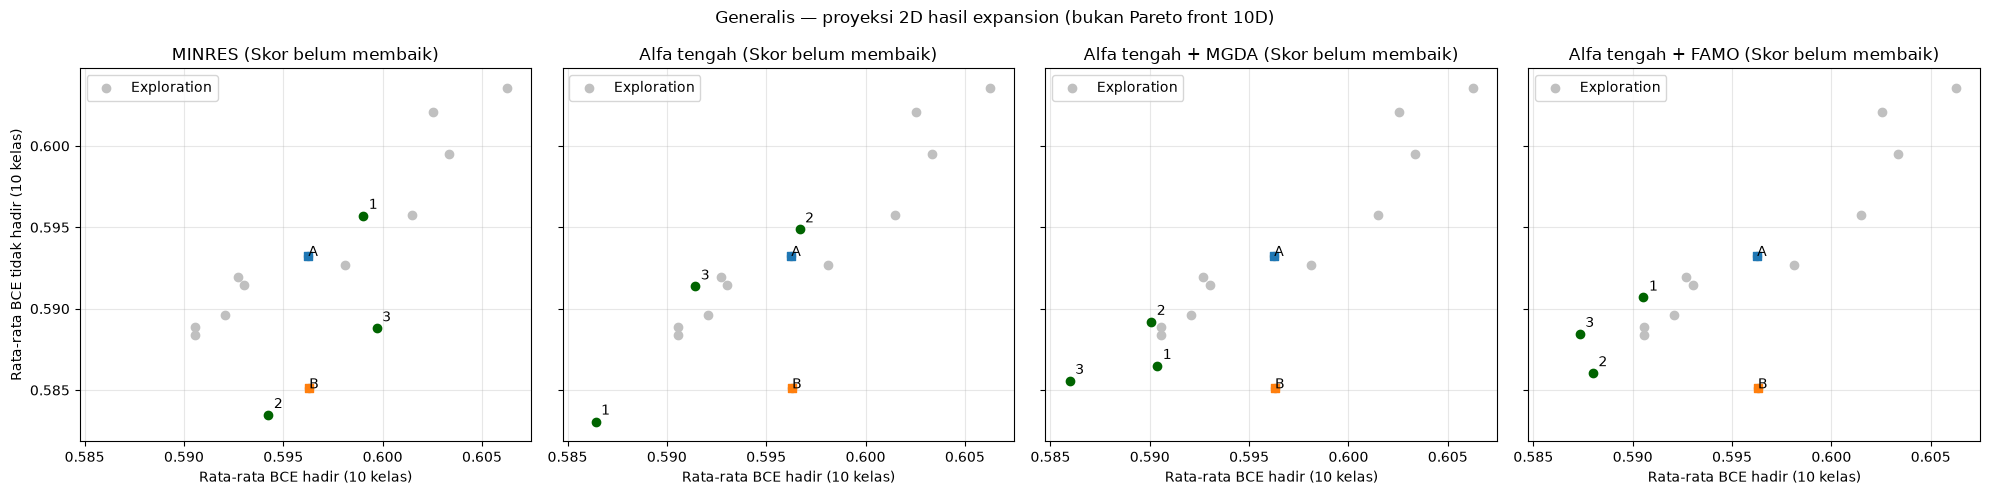

In [43]:
# Expansion pada proyeksi 2D; kedua panel menggunakan skala X dan Y sama.
all_points = gen_pool + [p for extra, _, _ in gen_results.values() for p in extra]
all_xy = np.array([p['xy'] for p in all_points])
lo, hi = all_xy.min(axis=0), all_xy.max(axis=0)
margin = np.maximum((hi - lo) * 0.06, 1e-4)
names = [name for name in gen_results if name != 'Tanpa expand']
fig, panels = plt.subplots(1, len(names), figsize=(5 * len(names), 5),
                          sharex=True, sharey=True)
panels = np.atleast_1d(panels)
for ax, name in zip(panels, names):
    ax.scatter(*np.array([p['xy'] for p in gen_pool]).T,
               color='silver', label='Exploration')
    if gen_pair is not None:
        for label, point in zip(('A', 'B'), gen_pair):
            ax.scatter(*point['xy'], marker='s', zorder=3)
            ax.annotate(label, point['xy'])
    for r, point in enumerate(gen_results[name][0], 1):
        ax.scatter(*point['xy'], color='darkgreen', zorder=4)
        ax.annotate(str(r), point['xy'], xytext=(4, 5), textcoords='offset points')
    ax.set(title=f'{name} ({gen_results[name][2]})',
           xlim=(lo[0]-margin[0], hi[0]+margin[0]),
           ylim=(lo[1]-margin[1], hi[1]+margin[1]),
           xlabel='Rata-rata BCE hadir (10 kelas)')
    ax.grid(alpha=0.3)
    ax.legend()
panels[0].set_ylabel('Rata-rata BCE tidak hadir (10 kelas)')
fig.suptitle('Generalis — proyeksi 2D hasil expansion (bukan Pareto front 10D)')
plt.tight_layout()
plt.show()


Generalis | kandidat per metode | skor validasi 10 tugas (minimax)
PCGrad       |  4 | 0.64315
MGDA         |  4 | 0.62786
FAMO         |  4 | 0.64772
MINRES       |  3 | 0.63013 | Skor belum membaik | 0.6s
Alfa tengah  |  3 | 0.63547 | Skor belum membaik | 0.7s
Alfa tengah + MGDA |  3 | 0.65866 | Skor belum membaik | 6.0s
Alfa tengah + FAMO |  3 | 0.66033 | Skor belum membaik | 1.8s

GENERALIS TERPILIH: MGDA
Validasi 10 objektif: [0.6052 0.5613 0.5611 0.6276 0.6279 0.5847 0.6217 0.5976 0.559  0.5609]
Validasi proyeksi hadir/tidak: [0.5963 0.5851]
Validasi minimax 10 kelas: 0.62786
Test 10 objektif: [0.5634 0.5567 0.5498 0.6379 0.5985 0.567  0.6314 0.6178 0.5726 0.557 ]
Test proyeksi hadir/tidak: [0.5899 0.5805]
Model Generalist disimpan: fashion_cnn_teachers\generalist_best.pt


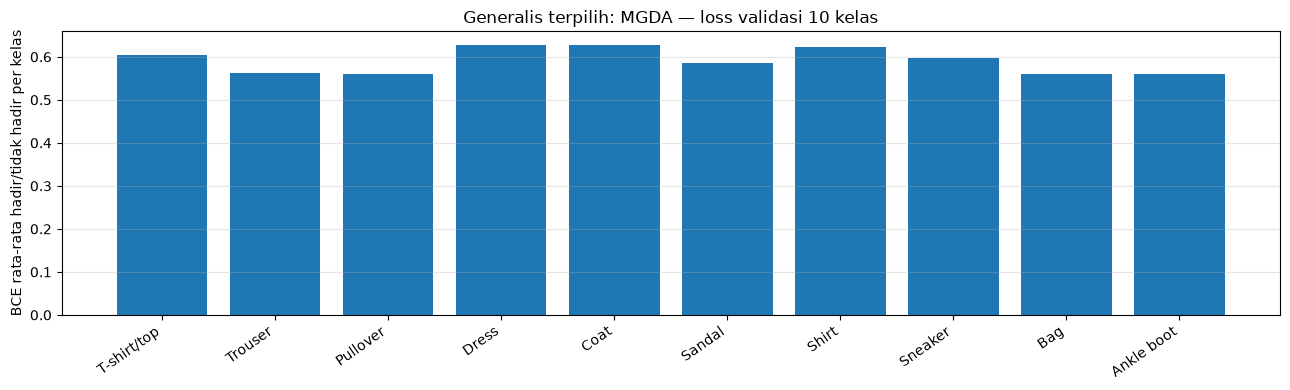

In [44]:
# Pilih Generalist terbaik menggunakan validasi 10 objektif, bukan hasil test.
all_gen_candidates = gen_pool + [p for extra, _, _ in gen_results.values() for p in extra]
gen_winner = min(all_gen_candidates, key=lambda p: p['score'])
gen_best_model = deepcopy(gen_initial)
gen_best_model.load_state_dict(gen_winner['state'])
gen_best_model.eval()
gen_test_objectives, gen_test_xy = evaluate(
    gen_best_model, gen_test, return_components=True
)

print('Generalis | kandidat per metode | skor validasi 10 tugas (minimax)')
for method in ('PCGrad', 'MGDA', 'FAMO'):
    best = min(gen_paths[method], key=lambda p: p['score'])
    print(f'{method:12} | {len(gen_paths[method]):2} | {best["score"]:.5f}')
for name in ('MINRES', 'Alfa tengah', 'Alfa tengah + MGDA',
             'Alfa tengah + FAMO'):
    extra, seconds, reason = gen_results[name]
    best = min(extra, key=lambda p: p['score']) if extra else None
    print(f'{name:12} | {len(extra):2} | '
          f'{best["score"] if best else float("nan"):.5f} | {reason} | {seconds:.1f}s')

print('\nGENERALIS TERPILIH:', gen_winner['name'])
print('Validasi 10 objektif:', np.round(gen_winner['objectives'], 4))
print('Validasi proyeksi hadir/tidak:', np.round(gen_winner['xy'], 4))
print('Validasi minimax 10 kelas:', round(gen_winner['score'], 5))
print('Test 10 objektif:', np.round(gen_test_objectives, 4))
print('Test proyeksi hadir/tidak:', np.round(gen_test_xy, 4))

# Simpan model Generalist terpilih terpisah dari teacher.
if CFG['SAVE_TEACHERS']:
    from pathlib import Path
    output_path = Path(CFG['TEACHER_DIR']) / 'generalist_best.pt'
    output_path.parent.mkdir(parents=True, exist_ok=True)
    torch.save({
        'architecture': 'Generalist-CNN-10heads',
        'selected_method': gen_winner['name'],
        'valid_objectives': gen_winner['objectives'].tolist(),
        'valid_projection_xy': gen_winner['xy'].tolist(),
        'score': gen_winner['score'],
        'alpha': None if gen_winner['alpha'] is None else gen_winner['alpha'].tolist(),
        'state_dict': gen_winner['state'],
    }, output_path)
    print('Model Generalist disimpan:', output_path)

fig, ax = plt.subplots(figsize=(13, 4))
ax.bar(np.arange(len(CLASS_NAMES)), gen_winner['objectives'])
ax.set_xticks(np.arange(len(CLASS_NAMES)), CLASS_NAMES, rotation=35, ha='right')
ax.set(title=f'Generalis terpilih: {gen_winner["name"]} — loss validasi 10 kelas',
       ylabel='BCE rata-rata hadir/tidak hadir per kelas')
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


## Catatan implementasi dan perubahan penting

1. **Backbone semua Specialist dan Generalist kembali ke CNN ringan**, satu Conv2d dengan Softplus (bukan ResNet-18). Input tetap `(B,1,56,56)`, fitur 32, dan output head tidak berubah.
2. **10 Specialist tetap** menjalankan exploration PCGrad/MGDA/FAMO dan upaya expansion MINRES/Alfa tengah. Masing-masing Specialist tetap dua objektif hadir/tidak hadir untuk kelasnya sendiri.
3. **Generalis juga menjalankan semua lima metode**: PCGrad/MGDA/FAMO dan MINRES/Alfa tengah. Berbeda dari versi sebelumnya yang memakai dua objective global, sekarang **10 objective per kelas**, satu per head (rata-rata BCE kedua logit). Alpha FAMO/MGDA/MINRES/Alfa tengah memiliki 10 komponen, PCGrad memproyeksikan 10 gradien backbone.
4. **Checkpoint mencatat `objectives` (2 atau 10), `xy` (2D hanya untuk grafik), `score=max(objectives)`**. Pemilihan final Generalist memakai 10 objective, bukan proyeksi 2D. Validasi dan test tidak dicampur untuk pemilihan model.
5. **Pasangan expansion Generalist dipilih dari Pareto 10 dimensi**; fallback ditandai jelas dan tidak boleh disebut Pareto front. Dua grafik proyeksi generalis dipisahkan dengan skala sama, ditambah grafik loss untuk 10 kelas.
6. Progres per epoch dan per 100 batch ditampilkan (`PROGRESS_EVERY`) agar training panjang dapat dipantau. MINRES masih berpotensi membutuhkan waktu dan gagal secara numerik, tetapi CNN memperkecil beban secara besar.
7. Model teacher terpilih disimpan ke `fashion_cnn_teachers/`, dan model Generalist terpilih ke `fashion_cnn_teachers/generalist_best.pt`. Berkas dari versi ResNet-18 tidak kompatibel dengan bobot CNN ini.
8. Semua teacher tetap digunakan untuk membuat target lunak Generalist. Jika suatu metode expansion gagal/tidak menghasilkan kandidat, alasan dilaporkan dan pemilihan menggunakan checkpoint validasi yang berhasil ada.
